# DrugBank XML Parsing

## Objective

The objective of this notebook is to extract useful information from the DrugBank XML database and convert it into a structured CSV file for machine learning.

---

## Workflow

Open XML

↓

Read one drug

↓

Extract required fields

↓

Write to CSV

↓

Repeat until the end

In [1]:
import xml.etree.ElementTree as ET
import csv

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_basic.csv"

NS = "{http://www.drugbank.ca}"

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)

    writer.writerow([
        "drugbank_id",
        "name",
        "description",
        "indication",
        "mechanism_of_action"
    ])

    for event, drug in ET.iterparse(XML_FILE, events=("end",)):
        if drug.tag == NS + "drug":

            drug_id = drug.findtext(NS + "drugbank-id", default="")
            name = drug.findtext(NS + "name", default="")
            description = drug.findtext(NS + "description", default="")
            indication = drug.findtext(NS + "indication", default="")
            mechanism = drug.findtext(NS + "mechanism-of-action", default="")

            writer.writerow([
                drug_id,
                name,
                description,
                indication,
                mechanism
            ])

            drug.clear()

print("Finished. CSV file created:")
print(OUTPUT_FILE)

Finished. CSV file created:
/Users/sankhadeep/Desktop/DrugBank/drugbank_basic.csv


# Step 1 - Reading DrugBank XML

## Objective

The objective of this notebook is to read the DrugBank XML database and extract only the DrugBank ID and Drug Name.

This is the first step in building a structured dataset for machine learning.

### Expected Output

A CSV file containing two columns:

- DrugBank ID
- Drug Name

In [2]:
import xml.etree.ElementTree as ET
import csv

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step1.csv"

NS = "{http://www.drugbank.ca}"

csvfile = open(OUTPUT_FILE, "w", newline="", encoding="utf-8")

writer = csv.writer(csvfile)

writer.writerow(["DrugBank_ID", "Drug_Name"])

print("CSV created successfully.")


context = ET.iterparse(XML_FILE, events=("end",))

for event, elem in context:

    if elem.tag == NS + "drug":

        drug_id = elem.findtext(NS + "drugbank-id")

        drug_name = elem.findtext(NS + "name")

        print(drug_id, drug_name)

        break


writer.writerow([drug_id, drug_name])

csvfile.close()

print("Finished.")

CSV created successfully.
DB00001 Lepirudin
Finished.


# Step 2 – Extract All DrugBank IDs and Drug Names

## Objective

The objective of this step is to read the complete DrugBank XML database and extract the DrugBank ID and Drug Name for every drug. Unlike Step 1, where only the first drug record was extracted for testing purposes, this step processes the entire XML file.

The extracted information is stored in a CSV file, which serves as the first structured dataset for subsequent preprocessing and machine learning tasks.

### Workflow

1. Import the required Python libraries.
2. Specify the location of the DrugBank XML file.
3. Create a CSV file with appropriate column headers.
4. Parse the XML file sequentially using `iterparse()`.
5. For each `<drug>` element:
   - Extract the DrugBank ID.
   - Extract the Drug Name.
   - Write the extracted values into the CSV file.
6. Count the total number of drugs extracted.
7. Save the CSV file.
8. Verify the output by displaying the first five records, the dataset dimensions, and the last five records.

### Expected Output

A CSV file named **drugbank_step2_all_drugs.csv** containing two columns:

- DrugBank_ID
- Drug_Name

The number of extracted rows should approximately equal the total number of drug records present in the DrugBank XML database.

In [3]:
# ============================================================
# Step 2 - Extract All DrugBank IDs and Drug Names
# ============================================================

# Import required libraries
import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define file paths
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_all_drugs.csv"

# DrugBank XML Namespace
NS = "{http://www.drugbank.ca}"

# Counter for total drugs
count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV file
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # CSV Header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Read the XML sequentially
    # --------------------------------------------------------

    for event, elem in ET.iterparse(XML_FILE, events=("end",)):

        # Process only <drug> elements
        if elem.tag == NS + "drug":

            # Extract DrugBank ID
            drug_id = elem.findtext(NS + "drugbank-id", default="")

            # Extract Drug Name
            drug_name = elem.findtext(NS + "name", default="")

            # Write into CSV
            writer.writerow([
                drug_id,
                drug_name
            ])

            # Increase counter
            count += 1

            # Free memory
            elem.clear()

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)
print("CSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the extracted CSV
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 3963134
CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_all_drugs.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID      Drug_Name
0     DB00001      Lepirudin
1     DB01022  Phylloquinone
2     DB01373        Calcium
3     DB00001      Lepirudin
4     DB00002      Cetuximab

Dataset Shape
(3963134, 2)

Last Five Records
        DrugBank_ID                     Drug_Name
3963129     DB32724                       SCY-247
3963130     DB32725              Tripentadecanoin
3963131     DB32726  Propylene glycol dicaprylate
3963132     DB32727                      RCT-1213
3963133     DB32728                 Cerous cation


# XML Structure Inspection

## Objective

Before extracting data from the DrugBank XML database, it is important to understand its hierarchical structure.

The purpose of this notebook is to inspect the XML tree and determine where the top-level `<drug>` elements are located.

Understanding the XML hierarchy helps avoid extracting nested elements unintentionally.

In [4]:
import xml.etree.ElementTree as ET

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

tree = ET.parse(XML_FILE)

root = tree.getroot()

print("Root tag:")
print(root.tag)

print()

print("First 20 child elements of the root:\n")

for child in list(root)[:20]:
    print(child.tag)

Root tag:
{http://www.drugbank.ca}drugbank

First 20 child elements of the root:

{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug
{http://www.drugbank.ca}drug


# Step 2 (Corrected) – Extract Only the Top-Level Drug Records

## Objective

In the previous step, every XML element named `<drug>` was extracted, resulting in approximately 3.9 million records. However, DrugBank contains only around 17,000 unique drugs. This indicates that the XML file contains additional nested `<drug>` elements that should not be treated as independent drug records.

The objective of this step is to extract only the **top-level `<drug>` elements**, which are direct children of the root `<drugbank>` element.

To achieve this, the XML tree depth is monitored while parsing the document. Only `<drug>` elements that occur at the second level of the XML hierarchy are processed.

The following operations are performed:

1. Import the required Python libraries.
2. Define the locations of the XML and CSV files.
3. Create an output CSV file.
4. Read the DrugBank XML sequentially using `iterparse()`.
5. Track the XML depth during parsing.
6. Extract only top-level drug records.
7. Store the DrugBank ID and Drug Name in a CSV file.
8. Count the number of extracted drugs.
9. Load the generated CSV using pandas for verification.

## Expected Output

A CSV file named **drugbank_step2_corrected.csv** containing only the unique top-level DrugBank records.

The output should contain approximately **17,000** rows with two columns:

- DrugBank_ID
- Drug_Name

This dataset will serve as the foundation for extracting additional attributes such as descriptions, indications, targets, pathways, enzymes, transporters and drug interactions in the subsequent steps.

In [5]:
# ============================================================
# Step 2 (Corrected)
# Extract Only Top-Level DrugBank Drug Records
# ============================================================

# ------------------------------------------------------------
# Import Required Libraries
# ------------------------------------------------------------

import xml.etree.ElementTree as ET
import csv
import pandas as pd

# ------------------------------------------------------------
# Define File Locations
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_corrected.csv"

# DrugBank XML Namespace
NS = "{http://www.drugbank.ca}"

# ------------------------------------------------------------
# Initialize Counter
# ------------------------------------------------------------

count = 0

print("Creating CSV file...")

# ------------------------------------------------------------
# Create CSV File
# ------------------------------------------------------------

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    # Write CSV Header
    writer.writerow([
        "DrugBank_ID",
        "Drug_Name"
    ])

    print("Reading DrugBank XML...")

    # --------------------------------------------------------
    # Parse XML
    # --------------------------------------------------------

    context = ET.iterparse(
        XML_FILE,
        events=("start", "end")
    )

    depth = 0

    for event, elem in context:

        # Entering an XML element
        if event == "start":
            depth += 1

        # Leaving an XML element
        elif event == "end":

            # Process only top-level <drug> elements
            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(
                    NS + "drugbank-id",
                    default=""
                )

                drug_name = elem.findtext(
                    NS + "name",
                    default=""
                )

                writer.writerow([
                    drug_id,
                    drug_name
                ])

                count += 1

                # Release memory
                elem.clear()

            depth -= 1

# ------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

# ------------------------------------------------------------
# Verify the Output
# ------------------------------------------------------------

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step2_corrected.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name
0     DB00001            Lepirudin
1     DB00002            Cetuximab
2     DB00003         Dornase alfa
3     DB00004  Denileukin diftitox
4     DB00005           Etanercept

Dataset Shape
(19856, 2)

Last Five Records
      DrugBank_ID                     Drug_Name
19851     DB32724                       SCY-247
19852     DB32725              Tripentadecanoin
19853     DB32726  Propylene glycol dicaprylate
19854     DB32727                      RCT-1213
19855     DB32728                 Cerous cation


# Step 3 – Extract DrugBank ID, Drug Name, and Description

## Objective

The objective of this step is to extend the corrected DrugBank XML parser by extracting the drug description along with the DrugBank ID and Drug Name.

The drug description provides useful background information about each drug, including its biological, chemical, or therapeutic characteristics. This information may later support feature engineering, text analysis, or natural language processing tasks in the drug repurposing workflow.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only top-level `<drug>` records.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
4. Save the extracted data into a CSV file.
5. Verify the output using pandas.

## Expected Output

A CSV file named **drugbank_step3_description.csv** containing three columns:

- DrugBank_ID
- Drug_Name
- Description

The number of rows should remain the same as Step 2, approximately **19,856** records.

In [6]:
# ============================================================
# Step 3
# Extract DrugBank ID, Drug Name, and Description
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step3_description.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")

                writer.writerow([
                    drug_id,
                    drug_name,
                    description
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...



Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step3_description.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  
0  Lepirudin is a recombinant hirudin formed by 6...  
1  Cetuximab is a recombinant chimeric human/mous...  
2  Dornase alfa is a biosynthetic form of human d...  
3  Denileukin diftitox is an IL2-receptor-directe...  
4  Dimeric fusion protein consisting of the extra...  

Dataset Shape
(19856, 3)

Missing Values
DrugBank_ID       0
Drug_Name         0
Description    7406
dtype: int64

Last Five Records
      DrugBank_ID                     Drug_Name  \
19851     DB32724       

# Step 4 – Extract DrugBank ID, Drug Name, Description, and Indication

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting the **Indication** field in addition to the DrugBank ID, Drug Name, and Description.

The indication field is especially important for drug repurposing because it describes the current therapeutic use of a drug, including the diseases or medical conditions for which the drug is used.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only top-level `<drug>` records.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
4. Save the extracted data into a CSV file.
5. Verify the output using pandas.

## Expected Output

A CSV file named **drugbank_step4_indication.csv** containing four columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication

The number of rows should remain the same as the previous step, approximately **19,856** records.

In [7]:
# ============================================================
# Step 4
# Extract DrugBank ID, Drug Name, Description, and Indication
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step4_indication.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step4_indication.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  
0  Lepirudin is indicated for anticoagulation in ...  
1  Cetuximab is indicated for: \r\n\r\n- The tre

# Step 5 – Extract DrugBank ID, Drug Name, Description, Indication, and Mechanism of Action

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting the **Mechanism of Action** field in addition to the DrugBank ID, Drug Name, Description, and Indication.

The mechanism of action explains how a drug produces its biological or therapeutic effect. This information is important for drug repurposing because drugs with similar mechanisms may be useful for treating similar or related diseases.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only top-level `<drug>` records.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
4. Save the extracted data into a CSV file.
5. Verify the output using pandas.

## Expected Output

A CSV file named **drugbank_step5_mechanism.csv** containing five columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action

The number of rows should remain the same as the previous step, approximately **19,856** records.

In [8]:
# ============================================================
# Step 5
# Extract DrugBank ID, Drug Name, Description, Indication,
# and Mechanism of Action
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step5_mechanism.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step5_mechanism.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The tr

# Step 6 – Extract Drug Targets

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting **drug target information**.

Drug targets are important for drug repurposing because they describe the proteins or biological molecules that a drug acts on. Drugs that share similar targets may have similar therapeutic effects or may be candidates for new disease applications.

This step extracts:

- DrugBank ID
- Drug Name
- Description
- Indication
- Mechanism of Action
- Target Names

Because one drug may have multiple targets, all target names for a drug are combined into a single text field separated by semicolons.

## Expected Output

A CSV file named **drugbank_step6_targets.csv** containing six columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets

The number of rows should remain approximately **19,856** records.

In [9]:
# ============================================================
# Step 6
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, and Drug Targets
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step6_targets.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):
                        target_name = target.findtext(NS + "name", default="")
                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step6_targets.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The trea

# Step 7 – Extract Drug Pathways

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting **pathway information**.

Drug pathways are important for drug repurposing because they describe the biological or metabolic pathways associated with a drug. Pathway information can help identify relationships between drugs, biological processes, and disease mechanisms.

This step extracts:

- DrugBank ID
- Drug Name
- Description
- Indication
- Mechanism of Action
- Targets
- Pathways

Because one drug may be associated with multiple pathways, all pathway names for each drug are combined into a single text field separated by semicolons.

## Expected Output

A CSV file named **drugbank_step7_pathways.csv** containing seven columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways

The number of rows should remain approximately **19,856** records.

In [10]:
# ============================================================
# Step 7
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, Targets, and Pathways
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step7_pathways.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                target_names = []
                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):
                        target_name = target.findtext(NS + "name", default="")
                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                pathway_names = []
                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:
                    for pathway in pathways_element.findall(NS + "pathway"):
                        pathway_name = pathway.findtext(NS + "name", default="")
                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step7_pathways.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The tre

# Step 8 – Extract Drug Categories

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting **drug category information**.

Drug categories are useful for drug repurposing because they describe the pharmacological or therapeutic class of a drug. Drugs belonging to similar categories may share related biological effects or therapeutic applications.

This step extracts:

- DrugBank ID
- Drug Name
- Description
- Indication
- Mechanism of Action
- Targets
- Pathways
- Categories

Because one drug may belong to multiple categories, all category names for each drug are combined into a single text field separated by semicolons.

## Expected Output

A CSV file named **drugbank_step8_categories.csv** containing eight columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways
- Categories

The number of rows should remain approximately **19,856** records.

In [11]:
# ============================================================
# Step 8
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, Targets, Pathways, and Categories
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step8_categories.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                target_names = []
                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):
                        target_name = target.findtext(NS + "name", default="")
                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                pathway_names = []
                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:
                    for pathway in pathways_element.findall(NS + "pathway"):
                        pathway_name = pathway.findtext(NS + "name", default="")
                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                category_names = []
                categories_element = elem.find(NS + "categories")

                if categories_element is not None:
                    for category in categories_element.findall(NS + "category"):
                        category_name = category.findtext(NS + "category", default="")
                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text
                ])

                count += 1
                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step8_categories.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The t

# Step 9 – Extract ATC Codes

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting the Anatomical Therapeutic Chemical (ATC) classification codes.

The ATC classification system is an internationally recognized drug classification system developed by the World Health Organization (WHO). It categorizes drugs according to the organ or system on which they act, their therapeutic use, pharmacological properties, and chemical characteristics.

This information is valuable for drug repurposing because drugs belonging to similar ATC classes often exhibit similar therapeutic effects and mechanisms of action.

This step extracts:

- DrugBank ID
- Drug Name
- Description
- Indication
- Mechanism of Action
- Targets
- Pathways
- Categories
- ATC Codes

Since a drug may have multiple ATC codes, all codes are combined into a single text field separated by semicolons.

## Expected Output

A CSV file named **drugbank_step9_atc.csv** containing the following columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways
- Categories
- ATC_Codes

The number of rows should remain approximately **19,856**.

In [12]:
# ============================================================
# Step 9
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, Targets, Pathways, Categories,
# and ATC Codes
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step9_atc.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories",
        "ATC_Codes"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                # ---------------- Targets ----------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):
                        target_name = target.findtext(NS + "name", default="")
                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # ---------------- Pathways ----------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:
                    for pathway in pathways_element.findall(NS + "pathway"):
                        pathway_name = pathway.findtext(NS + "name", default="")
                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # ---------------- Categories ----------------

                category_names = []

                categories_element = elem.find(NS + "categories")

                if categories_element is not None:
                    for category in categories_element.findall(NS + "category"):
                        category_name = category.findtext(NS + "category", default="")
                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                # ---------------- ATC Codes ----------------

                atc_codes = []

                atc_element = elem.find(NS + "atc-codes")

                if atc_element is not None:
                    for atc in atc_element.findall(NS + "atc-code"):

                        code = atc.get("code")

                        if code:
                            atc_codes.append(code)

                atc_text = "; ".join(atc_codes)

                # ---------------- Write Row ----------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text,
                    atc_text
                ])

                count += 1

                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step9_atc.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The trea... 

# Step 10 – Exploratory Data Assessment of the Extracted DrugBank Dataset

## Objective

The objective of this step is to examine the structured DrugBank dataset created in the previous steps.

Before using the dataset for machine learning, it is important to check:

1. Dataset size
2. Column names
3. Missing values
4. Duplicate DrugBank IDs
5. Number of available values in each feature
6. Basic quality of extracted fields

This step helps verify whether the extracted dataset is suitable for further preprocessing and feature engineering.

In [13]:
# ============================================================
# Step 10
# Exploratory Data Assessment of DrugBank Extracted Dataset
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Load the extracted dataset
# ------------------------------------------------------------

FILE_PATH = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step9_atc.csv"

df = pd.read_csv(FILE_PATH)

# ------------------------------------------------------------
# 1. Dataset shape
# ------------------------------------------------------------

print("Dataset Shape:")
print(df.shape)

# ------------------------------------------------------------
# 2. Column names
# ------------------------------------------------------------

print("\nColumn Names:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. First five records
# ------------------------------------------------------------

print("\nFirst Five Records:")
print(df.head())

# ------------------------------------------------------------
# 4. Last five records
# ------------------------------------------------------------

print("\nLast Five Records:")
print(df.tail())

# ------------------------------------------------------------
# 5. Missing values
# ------------------------------------------------------------

print("\nMissing Values:")
print(df.isnull().sum())

# ------------------------------------------------------------
# 6. Missing value percentage
# ------------------------------------------------------------

print("\nMissing Value Percentage:")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

# ------------------------------------------------------------
# 7. Duplicate DrugBank IDs
# ------------------------------------------------------------

duplicate_ids = df["DrugBank_ID"].duplicated().sum()

print("\nDuplicate DrugBank IDs:")
print(duplicate_ids)

# ------------------------------------------------------------
# 8. Number of unique drugs
# ------------------------------------------------------------

unique_drugs = df["DrugBank_ID"].nunique()

print("\nNumber of Unique DrugBank IDs:")
print(unique_drugs)

# ------------------------------------------------------------
# 9. Count available values per column
# ------------------------------------------------------------

print("\nNon-Missing Values Per Column:")
print(df.notnull().sum())

# ------------------------------------------------------------
# 10. Summary
# ------------------------------------------------------------

print("\nSummary:")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Unique drugs:", unique_drugs)
print("Duplicate IDs:", duplicate_ids)

Dataset Shape:
(19856, 9)

Column Names:
['DrugBank_ID', 'Drug_Name', 'Description', 'Indication', 'Mechanism_of_Action', 'Targets', 'Pathways', 'Categories', 'ATC_Codes']

First Five Records:
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The trea...   
2  Used as adjunct therapy in the treatment of cy...   
3  Denileukin dif

# Understanding SMILES

## What is SMILES?

SMILES (Simplified Molecular Input Line Entry System) is a text-based notation used to represent the chemical structure of a molecule. Instead of storing a molecule as a graphical chemical diagram, SMILES encodes the molecular structure as a sequence of characters that can be easily processed by computers.

For example:

| Molecule | SMILES |
|----------|---------|
| Water | `O` |
| Ethanol | `CCO` |
| Benzene | `c1ccccc1` |
| Aspirin | `CC(=O)OC1=CC=CC=C1C(=O)O` |

Each character or symbol represents atoms, chemical bonds, branching, ring structures, and other molecular properties.

## Why is SMILES Important?

SMILES is one of the most widely used molecular representations in cheminformatics and computational drug discovery. Since machine learning algorithms cannot directly process chemical structure diagrams, SMILES provides a standardized text representation that can be used for computational analysis.

Using SMILES, researchers can calculate a wide range of molecular descriptors, including:

- Molecular weight
- Number of atoms
- Number of rings
- Hydrogen bond donors
- Hydrogen bond acceptors
- LogP (lipophilicity)
- Molecular fingerprints
- Topological descriptors

These descriptors are commonly used as input features for machine learning models in drug discovery and drug repurposing.

## Why is SMILES Relevant to This Dissertation?

The objective of this dissertation is to identify potential opportunities for drug repurposing using machine learning techniques. Although the current study focuses on extracting information from DrugBank, the SMILES representation provides an important link between the biological information stored in DrugBank and the chemical structure of each drug.

By extracting the SMILES representation, it becomes possible to generate molecular descriptors and fingerprints using cheminformatics libraries such as RDKit. These features can later be incorporated into machine learning models to improve prediction performance and enable structure-based analysis of drug similarity.

## Where is SMILES Stored in DrugBank?

Unlike fields such as Drug Name or Indication, the SMILES representation is not stored as a direct child element of each drug. Instead, it is stored within the **Calculated Properties** section of the DrugBank XML file.

The XML structure is similar to the following:

```xml
<calculated-properties>
    <property>
        <kind>SMILES</kind>
        <value>CC(=O)OC1=CC=CC=C1C(=O)O</value>
    </property>
</calculated-properties>
```

Therefore, extracting SMILES requires searching through the calculated properties of each drug and identifying the property whose `<kind>` element is equal to **SMILES**.

# Step 11 – Extract SMILES Representation

## Objective

The objective of this step is to extend the DrugBank XML parser by extracting the **SMILES (Simplified Molecular Input Line Entry System)** representation for each drug.

SMILES is a text-based representation of a molecule's chemical structure and is one of the most widely used molecular representations in cheminformatics. Unlike the descriptive information extracted in the previous steps, SMILES provides structural information about each drug molecule.

The extracted SMILES strings can later be used to generate molecular descriptors, molecular fingerprints, and other chemical features using cheminformatics libraries such as RDKit. These features are commonly used as inputs to machine learning models for drug discovery and drug repurposing.

This step performs the following operations:

1. Read the DrugBank XML file.
2. Process only the top-level `<drug>` elements.
3. Extract:
   - DrugBank ID
   - Drug Name
   - Description
   - Indication
   - Mechanism of Action
   - Targets
   - Pathways
   - Categories
   - ATC Codes
   - SMILES
4. Save the extracted information into a CSV file.
5. Verify the extracted dataset using pandas.

## Expected Output

A CSV file named **drugbank_step11_smiles.csv** containing ten columns:

- DrugBank_ID
- Drug_Name
- Description
- Indication
- Mechanism_of_Action
- Targets
- Pathways
- Categories
- ATC_Codes
- SMILES

The number of rows should remain approximately **19,856** records.

In [14]:
# ============================================================
# Step 11
# Extract DrugBank ID, Drug Name, Description, Indication,
# Mechanism of Action, Targets, Pathways, Categories,
# ATC Codes and SMILES
# ============================================================

import xml.etree.ElementTree as ET
import csv
import pandas as pd

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"
OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_smiles.csv"

NS = "{http://www.drugbank.ca}"

count = 0

print("Creating CSV file...")

with open(OUTPUT_FILE, "w", newline="", encoding="utf-8") as csvfile:

    writer = csv.writer(csvfile)

    writer.writerow([
        "DrugBank_ID",
        "Drug_Name",
        "Description",
        "Indication",
        "Mechanism_of_Action",
        "Targets",
        "Pathways",
        "Categories",
        "ATC_Codes",
        "SMILES"
    ])

    print("Reading DrugBank XML...")

    context = ET.iterparse(XML_FILE, events=("start", "end"))

    depth = 0

    for event, elem in context:

        if event == "start":
            depth += 1

        elif event == "end":

            if elem.tag == NS + "drug" and depth == 2:

                drug_id = elem.findtext(NS + "drugbank-id", default="")
                drug_name = elem.findtext(NS + "name", default="")
                description = elem.findtext(NS + "description", default="")
                indication = elem.findtext(NS + "indication", default="")
                mechanism = elem.findtext(NS + "mechanism-of-action", default="")

                # ---------------- Targets ----------------

                target_names = []

                targets_element = elem.find(NS + "targets")

                if targets_element is not None:
                    for target in targets_element.findall(NS + "target"):
                        target_name = target.findtext(NS + "name", default="")
                        if target_name:
                            target_names.append(target_name)

                targets_text = "; ".join(target_names)

                # ---------------- Pathways ----------------

                pathway_names = []

                pathways_element = elem.find(NS + "pathways")

                if pathways_element is not None:
                    for pathway in pathways_element.findall(NS + "pathway"):
                        pathway_name = pathway.findtext(NS + "name", default="")
                        if pathway_name:
                            pathway_names.append(pathway_name)

                pathways_text = "; ".join(pathway_names)

                # ---------------- Categories ----------------

                category_names = []

                categories_element = elem.find(NS + "categories")

                if categories_element is not None:
                    for category in categories_element.findall(NS + "category"):
                        category_name = category.findtext(NS + "category", default="")
                        if category_name:
                            category_names.append(category_name)

                categories_text = "; ".join(category_names)

                # ---------------- ATC Codes ----------------

                atc_codes = []

                atc_element = elem.find(NS + "atc-codes")

                if atc_element is not None:
                    for atc in atc_element.findall(NS + "atc-code"):
                        code = atc.get("code")
                        if code:
                            atc_codes.append(code)

                atc_text = "; ".join(atc_codes)

                # ---------------- SMILES ----------------

                smiles = ""

                calculated_properties = elem.find(NS + "calculated-properties")

                if calculated_properties is not None:

                    for prop in calculated_properties.findall(NS + "property"):

                        kind = prop.findtext(NS + "kind", default="")

                        if kind == "SMILES":

                            smiles = prop.findtext(NS + "value", default="")

                            break

                # ---------------- Write Row ----------------

                writer.writerow([
                    drug_id,
                    drug_name,
                    description,
                    indication,
                    mechanism,
                    targets_text,
                    pathways_text,
                    categories_text,
                    atc_text,
                    smiles
                ])

                count += 1

                elem.clear()

            depth -= 1

print("\nExtraction Completed Successfully")
print("--------------------------------")
print("Total Drugs Extracted :", count)

print("\nCSV saved at:")
print(OUTPUT_FILE)

print("\nLoading CSV for verification...")

df = pd.read_csv(OUTPUT_FILE)

print("\nFirst Five Records")
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nLast Five Records")
print(df.tail())

Creating CSV file...
Reading DrugBank XML...

Extraction Completed Successfully
--------------------------------
Total Drugs Extracted : 19856

CSV saved at:
/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_smiles.csv

Loading CSV for verification...

First Five Records
  DrugBank_ID            Drug_Name  \
0     DB00001            Lepirudin   
1     DB00002            Cetuximab   
2     DB00003         Dornase alfa   
3     DB00004  Denileukin diftitox   
4     DB00005           Etanercept   

                                         Description  \
0  Lepirudin is a recombinant hirudin formed by 6...   
1  Cetuximab is a recombinant chimeric human/mous...   
2  Dornase alfa is a biosynthetic form of human d...   
3  Denileukin diftitox is an IL2-receptor-directe...   
4  Dimeric fusion protein consisting of the extra...   

                                          Indication  \
0  Lepirudin is indicated for anticoagulation in ...   
1  Cetuximab is indicated for: \r\n\r\n- The trea

# Step 12 – Data Cleaning and Preparation

## Objective

The objective of this step is to clean and prepare the DrugBank dataset extracted in Step 11 before proceeding to feature engineering and machine learning.

The previous data assessment confirmed that the dataset contains 19,856 unique DrugBank records with no duplicate DrugBank IDs. Therefore, duplicate DrugBank IDs are checked again in this step for verification.

Several extracted attributes contain missing values. Instead of removing drugs with missing information at this stage, the missing text values are standardized and additional indicator columns are created to identify the availability of important information for each drug.

This step performs the following operations:

1. Load the DrugBank dataset generated in Step 11.
2. Verify the number of duplicate and unique DrugBank IDs.
3. Standardize missing and blank values in the extracted text fields.
4. Create indicator columns to identify the availability of:
   - SMILES representations
   - Therapeutic indications
   - Drug targets
   - Pathways
   - Drug categories
   - ATC codes
   - Mechanism of action
   - Drug descriptions
5. Calculate the number and percentage of drugs for which each type of information is available.
6. Generate a summary table describing data availability.
7. Save the cleaned dataset for subsequent analysis and feature engineering.

## Expected Output

A cleaned DrugBank dataset named **drugbank_step12_cleaned.csv**.

The original DrugBank attributes are retained, and the following data availability indicator columns are added:

- Has_SMILES
- Has_Indication
- Has_Targets
- Has_Pathways
- Has_Categories
- Has_ATC
- Has_Mechanism
- Has_Description

No drug records are removed solely because of missing information at this stage. The cleaned dataset will be used in the subsequent stages to determine suitable records and features for drug repurposing analysis.

In [15]:
# ============================================================
# Step 12 – Data Cleaning and Preparation
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Define file paths
# ------------------------------------------------------------

INPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step11_smiles.csv"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step12_cleaned.csv"


# ------------------------------------------------------------
# Load the dataset
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("Original Dataset Shape:")
print(df.shape)


# ------------------------------------------------------------
# Check duplicate DrugBank IDs
# ------------------------------------------------------------

duplicate_count = df["DrugBank_ID"].duplicated().sum()

print("\nDuplicate DrugBank IDs:")
print(duplicate_count)

if duplicate_count == 0:
    print("No duplicate DrugBank IDs found.")
else:
    print("Warning: Duplicate DrugBank IDs are present.")


# ------------------------------------------------------------
# Check number of unique DrugBank IDs
# ------------------------------------------------------------

unique_drugs = df["DrugBank_ID"].nunique()

print("\nNumber of Unique DrugBank IDs:")
print(unique_drugs)


# ------------------------------------------------------------
# Standardise missing and blank text values
# ------------------------------------------------------------

text_columns = [
    "Drug_Name",
    "Description",
    "Indication",
    "Mechanism_of_Action",
    "Targets",
    "Pathways",
    "Categories",
    "ATC_Codes",
    "SMILES"
]

for column in text_columns:

    # Replace missing values with empty strings
    df[column] = df[column].fillna("")

    # Convert values to strings and remove
    # leading/trailing whitespace
    df[column] = df[column].astype(str).str.strip()


# ------------------------------------------------------------
# Create data availability indicators
# ------------------------------------------------------------

df["Has_SMILES"] = df["SMILES"].ne("")

df["Has_Indication"] = df["Indication"].ne("")

df["Has_Targets"] = df["Targets"].ne("")

df["Has_Pathways"] = df["Pathways"].ne("")

df["Has_Categories"] = df["Categories"].ne("")

df["Has_ATC"] = df["ATC_Codes"].ne("")

df["Has_Mechanism"] = df["Mechanism_of_Action"].ne("")

df["Has_Description"] = df["Description"].ne("")


# ------------------------------------------------------------
# Display data availability statistics
# ------------------------------------------------------------

print("\nData Availability")
print("-----------------------------")

print("Total Drugs:",
      len(df))

print("Drugs with SMILES:",
      df["Has_SMILES"].sum())

print("Drugs with Indication:",
      df["Has_Indication"].sum())

print("Drugs with Targets:",
      df["Has_Targets"].sum())

print("Drugs with Pathways:",
      df["Has_Pathways"].sum())

print("Drugs with Categories:",
      df["Has_Categories"].sum())

print("Drugs with ATC Codes:",
      df["Has_ATC"].sum())

print("Drugs with Mechanism of Action:",
      df["Has_Mechanism"].sum())

print("Drugs with Description:",
      df["Has_Description"].sum())


# ------------------------------------------------------------
# Calculate availability percentages
# ------------------------------------------------------------

print("\nData Availability Percentage")
print("-----------------------------")

availability_columns = [
    "Has_SMILES",
    "Has_Indication",
    "Has_Targets",
    "Has_Pathways",
    "Has_Categories",
    "Has_ATC",
    "Has_Mechanism",
    "Has_Description"
]

for column in availability_columns:

    percentage = df[column].mean() * 100

    print(
        f"{column}: {percentage:.2f}%"
    )


# ------------------------------------------------------------
# Create data availability summary table
# ------------------------------------------------------------

summary = pd.DataFrame({

    "Feature": [
        "SMILES",
        "Indication",
        "Targets",
        "Pathways",
        "Categories",
        "ATC Codes",
        "Mechanism of Action",
        "Description"
    ],

    "Available_Count": [
        df["Has_SMILES"].sum(),
        df["Has_Indication"].sum(),
        df["Has_Targets"].sum(),
        df["Has_Pathways"].sum(),
        df["Has_Categories"].sum(),
        df["Has_ATC"].sum(),
        df["Has_Mechanism"].sum(),
        df["Has_Description"].sum()
    ]
})


# ------------------------------------------------------------
# Calculate availability percentage
# ------------------------------------------------------------

summary["Available_Percentage"] = (
    summary["Available_Count"] / len(df)
) * 100

summary["Available_Percentage"] = (
    summary["Available_Percentage"].round(2)
)


print("\nData Availability Summary:")
print(summary)


# ------------------------------------------------------------
# Check final dataset shape
# ------------------------------------------------------------

print("\nCleaned Dataset Shape:")
print(df.shape)


# ------------------------------------------------------------
# Preview cleaned dataset
# ------------------------------------------------------------

print("\nFirst Five Records:")
print(df.head())


# ------------------------------------------------------------
# Save cleaned dataset
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nCleaned dataset saved at:")
print(OUTPUT_FILE)

Original Dataset Shape:
(19856, 10)

Duplicate DrugBank IDs:
0
No duplicate DrugBank IDs found.

Number of Unique DrugBank IDs:
19856

Data Availability
-----------------------------
Total Drugs: 19856
Drugs with SMILES: 14626
Drugs with Indication: 4484
Drugs with Targets: 10030
Drugs with Pathways: 1788
Drugs with Categories: 11140
Drugs with ATC Codes: 3636
Drugs with Mechanism of Action: 4257
Drugs with Description: 12450

Data Availability Percentage
-----------------------------
Has_SMILES: 73.66%
Has_Indication: 22.58%
Has_Targets: 50.51%
Has_Pathways: 9.00%
Has_Categories: 56.10%
Has_ATC: 18.31%
Has_Mechanism: 21.44%
Has_Description: 62.70%

Data Availability Summary:
               Feature  Available_Count  Available_Percentage
0               SMILES            14626                 73.66
1           Indication             4484                 22.58
2              Targets            10030                 50.51
3             Pathways             1788                  9.00
4    

In [16]:
# Check NaN values after cleaning
print("NaN values after cleaning:")
print(df[text_columns].isna().sum())

# Check empty strings after cleaning
print("\nEmpty strings after cleaning:")
print(df[text_columns].eq("").sum())

NaN values after cleaning:
Drug_Name              0
Description            0
Indication             0
Mechanism_of_Action    0
Targets                0
Pathways               0
Categories             0
ATC_Codes              0
SMILES                 0
dtype: int64

Empty strings after cleaning:
Drug_Name                  0
Description             7406
Indication             15372
Mechanism_of_Action    15599
Targets                 9826
Pathways               18068
Categories              8716
ATC_Codes              16220
SMILES                  5230
dtype: int64


# Step 13 – SMILES Validation

## Objective

The objective of this step is to validate the SMILES representations extracted from DrugBank before using them for molecular feature generation.

Step 12 showed that SMILES information is available for a substantial proportion of the DrugBank records. However, the presence of a SMILES value does not necessarily guarantee that the molecular representation is valid and can be successfully processed by cheminformatics tools.

In this step, the **RDKit** library is used to parse each available SMILES string and determine whether it represents a valid molecular structure.

Each DrugBank record is classified into one of the following categories:

- **Valid** – a SMILES value is available and can be successfully parsed by RDKit.
- **Invalid** – a SMILES value is available but cannot be parsed by RDKit.
- **Missing** – no SMILES value is available for the drug.

This step performs the following operations:

1. Load the cleaned DrugBank dataset generated in Step 12.
2. Check whether a SMILES representation is available for each drug.
3. Use RDKit to validate each available SMILES string.
4. Create a `Valid_SMILES` indicator column.
5. Create a `SMILES_Status` column to distinguish between valid, invalid, and missing SMILES.
6. Calculate the number and percentage of drugs in each SMILES validation category.
7. Save the validated dataset for subsequent molecular feature engineering.

## Expected Output

A CSV file named **drugbank_step13_smiles_validated.csv** containing all DrugBank records together with two additional columns:

- `Valid_SMILES`
- `SMILES_Status`

No DrugBank records are removed during this step. The validation results will be used in the next stage to identify molecules suitable for molecular descriptor and fingerprint generation.

In [17]:
%pip install rdkit


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
# ============================================================
# Step 13 – SMILES Validation
# ============================================================

import pandas as pd
from rdkit import Chem

print("RDKit imported successfully.")

# ------------------------------------------------------------
# Define file paths
# ------------------------------------------------------------

INPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step12_cleaned.csv"

OUTPUT_FILE = "/Users/sankhadeep/Desktop/DrugBank/drugbank_step13_smiles_validated.csv"


# ------------------------------------------------------------
# Load the cleaned dataset
# ------------------------------------------------------------

df = pd.read_csv(
    INPUT_FILE,
    keep_default_na=False
)

print("Dataset Shape:")
print(df.shape)


# ------------------------------------------------------------
# Function to determine SMILES status
# ------------------------------------------------------------

def validate_smiles(smiles):

    # Check whether SMILES is missing or blank
    if not isinstance(smiles, str) or smiles.strip() == "":
        return "Missing"

    # Try to convert the SMILES string into an RDKit molecule
    mol = Chem.MolFromSmiles(smiles)

    # If RDKit successfully creates a molecule
    if mol is not None:
        return "Valid"

    # SMILES exists but RDKit cannot parse it
    return "Invalid"


# ------------------------------------------------------------
# Validate SMILES
# ------------------------------------------------------------

df["SMILES_Status"] = df["SMILES"].apply(validate_smiles)


# ------------------------------------------------------------
# Create Boolean indicator for valid SMILES
# ------------------------------------------------------------

df["Valid_SMILES"] = df["SMILES_Status"].eq("Valid")


# ------------------------------------------------------------
# Count SMILES validation results
# ------------------------------------------------------------

valid_count = (df["SMILES_Status"] == "Valid").sum()

invalid_count = (df["SMILES_Status"] == "Invalid").sum()

missing_count = (df["SMILES_Status"] == "Missing").sum()

total_drugs = len(df)


# ------------------------------------------------------------
# Display validation results
# ------------------------------------------------------------

print("\nSMILES Validation Results")
print("-----------------------------")

print("Total Drugs:",
      total_drugs)

print("Valid SMILES:",
      valid_count)

print("Invalid SMILES:",
      invalid_count)

print("Missing SMILES:",
      missing_count)


# ------------------------------------------------------------
# Calculate percentages
# ------------------------------------------------------------

valid_percentage = (
    valid_count / total_drugs
) * 100

invalid_percentage = (
    invalid_count / total_drugs
) * 100

missing_percentage = (
    missing_count / total_drugs
) * 100


print("\nSMILES Validation Percentage")
print("-----------------------------")

print(
    f"Valid SMILES: {valid_percentage:.2f}%"
)

print(
    f"Invalid SMILES: {invalid_percentage:.2f}%"
)

print(
    f"Missing SMILES: {missing_percentage:.2f}%"
)


# ------------------------------------------------------------
# Create validation summary table
# ------------------------------------------------------------

smiles_summary = pd.DataFrame({

    "SMILES_Status": [
        "Valid",
        "Invalid",
        "Missing"
    ],

    "Count": [
        valid_count,
        invalid_count,
        missing_count
    ]
})


smiles_summary["Percentage"] = (
    smiles_summary["Count"] / total_drugs
) * 100


smiles_summary["Percentage"] = (
    smiles_summary["Percentage"].round(2)
)


print("\nSMILES Validation Summary:")
print(smiles_summary)


# ------------------------------------------------------------
# Verify that all records have been classified
# ------------------------------------------------------------

classified_total = (
    valid_count +
    invalid_count +
    missing_count
)

print("\nValidation Check:")
print("Total classified records:",
      classified_total)

print("Total dataset records:",
      total_drugs)


if classified_total == total_drugs:
    print("All DrugBank records were successfully classified.")
else:
    print("Warning: Some records were not classified.")


# ------------------------------------------------------------
# Preview validated records
# ------------------------------------------------------------

print("\nFirst Five Records:")
print(
    df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "SMILES",
            "SMILES_Status",
            "Valid_SMILES"
        ]
    ].head()
)


# ------------------------------------------------------------
# Save validated dataset
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nValidated Dataset Shape:")
print(df.shape)

print("\nValidated dataset saved at:")
print(OUTPUT_FILE)

RDKit imported successfully.
Dataset Shape:
(19856, 18)


[00:07:44] Explicit valence for atom # 13 Cl, 5, is greater than permitted
[00:07:44] SMILES Parse Error: syntax error while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O)(O)O)C1=CC=C(C=C1)S([O-])([O-])[O-])\C1=CC=C(C=C1)S(O)(O)[O-]
[00:07:44] SMILES Parse Error: check for mistakes around position 84:
[00:07:44] C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O
[00:07:44] ~~~~~~~~~~~~~~~~~~~~^
[00:07:44] SMILES Parse Error: extra open parentheses while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC=C(C=C1)S(O)(O)O)C1=CC=C(C=C1)S([O-])([O-])[O-])\C1=CC=C(C=C1)S(O)(O)[O-]
[00:07:44] SMILES Parse Error: check for mistakes around position 40:
[00:07:44] 1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2
[00:07:44] ~~~~~~~~~~~~~~~~~~~~^
[00:07:44] SMILES Parse Error: extra open parentheses while parsing: OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C


SMILES Validation Results
-----------------------------
Total Drugs: 19856
Valid SMILES: 14616
Invalid SMILES: 10
Missing SMILES: 5230

SMILES Validation Percentage
-----------------------------
Valid SMILES: 73.61%
Invalid SMILES: 0.05%
Missing SMILES: 26.34%

SMILES Validation Summary:
  SMILES_Status  Count  Percentage
0         Valid  14616       73.61
1       Invalid     10        0.05
2       Missing   5230       26.34

Validation Check:
Total classified records: 19856
Total dataset records: 19856
All DrugBank records were successfully classified.

First Five Records:
  DrugBank_ID            Drug_Name SMILES SMILES_Status  Valid_SMILES
0     DB00001            Lepirudin              Missing         False
1     DB00002            Cetuximab              Missing         False
2     DB00003         Dornase alfa              Missing         False
3     DB00004  Denileukin diftitox              Missing         False
4     DB00005           Etanercept              Missing         Fals

In [19]:
invalid_smiles = df[df["SMILES_Status"] == "Invalid"]

print(invalid_smiles[
    [
        "DrugBank_ID",
        "Drug_Name",
        "SMILES"
    ]
])

      DrugBank_ID                                          Drug_Name  \
1827      DB01929                5-Chloryl-2,4,6-quinazolinetriamine   
1896      DB01999  5,10,15,20-Tetrakis(4-Sulpfonatophenyl)-21h,23...   
2519      DB02667                           Vitamin B 12 factor IIIm   
3858      DB04100        Tricarbonyl(1,10-phenanthroline)rhenium(1+)   
4175      DB04444                           Tetrafluoroaluminate Ion   
7440      DB08276  trifluoro-[hydroxy-[hydroxy-[2-(N-methyl-2-nit...   
8478      DB09385                               Cyanocobalamin Co-57   
9763      DB11630                                         Temoporfin   
10563     DB12453                                   Chlorine dioxide   
15398     DB17408                                        Borocaptate   

                                                  SMILES  
1827              NC1=C(C2=C(N)N=C(N)N=C2C=C1)[Cl](=O)=O  
1896   OS(O)(O)C1=CC=C(C=C1)C-1=C2\C=CC(=N2)\C(=C2/N\...  
2519   COC1=CC=C2N(C=NC2=C1)[C

# Step 14 – Molecular Descriptor Generation

## Objective

The objective of this step is to generate numerical molecular descriptors from the valid SMILES representations identified in Step 13.

Molecular descriptors represent important physicochemical and structural properties of a molecule in numerical form. These numerical values can later be used as input features for machine learning models.

Only DrugBank records with valid SMILES representations are used for descriptor calculation. Records with missing or invalid SMILES are retained in the dataset, but their descriptor values remain missing.

The following molecular descriptors are calculated using RDKit:

- **Molecular Weight (MolWt)** – represents the molecular mass of the compound.
- **LogP** – represents the estimated lipophilicity of the molecule.
- **TPSA** – represents the topological polar surface area.
- **Hydrogen Bond Donors (HBD)** – number of groups capable of donating hydrogen bonds.
- **Hydrogen Bond Acceptors (HBA)** – number of groups capable of accepting hydrogen bonds.
- **Rotatable Bonds** – number of rotatable bonds, providing an indication of molecular flexibility.
- **Ring Count** – total number of rings present in the molecular structure.

This step performs the following operations:

1. Load the SMILES-validated dataset generated in Step 13.
2. Convert each valid SMILES representation into an RDKit molecular object.
3. Calculate the selected molecular descriptors.
4. Store the descriptor values as additional columns in the DrugBank dataset.
5. Leave descriptor values missing for drugs with invalid or unavailable SMILES.
6. Check the number of drugs for which molecular descriptors were successfully generated.
7. Save the resulting dataset for subsequent molecular feature analysis and machine learning.

## Expected Output

A CSV file named **drugbank_step14_molecular_descriptors.csv** containing the existing DrugBank information together with the following additional molecular descriptor columns:

- MolWt
- LogP
- TPSA
- HBD
- HBA
- Rotatable_Bonds
- Ring_Count

All original DrugBank records are retained. Molecular descriptor values are generated only for records containing valid SMILES representations.

In [20]:
# ============================================================
# Step 14 – Molecular Descriptor Generation
# ============================================================

import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import Lipinski
from rdkit.Chem import rdMolDescriptors


# ------------------------------------------------------------
# Define file paths
# ------------------------------------------------------------

INPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step13_smiles_validated.csv"
)

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_step14_molecular_descriptors.csv"
)


# ------------------------------------------------------------
# Load Step 13 dataset
# ------------------------------------------------------------

df = pd.read_csv(
    INPUT_FILE,
    keep_default_na=False
)

print("Dataset Shape:")
print(df.shape)


# ------------------------------------------------------------
# Function to calculate molecular descriptors
# ------------------------------------------------------------

def calculate_descriptors(smiles, valid_smiles):

    # Descriptors are calculated only for valid SMILES
    if not valid_smiles:
        return pd.Series([
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan
        ])

    # Convert SMILES into an RDKit molecule
    mol = Chem.MolFromSmiles(smiles)

    # Additional safety check
    if mol is None:
        return pd.Series([
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan,
            np.nan
        ])

    # Calculate molecular descriptors
    molecular_weight = Descriptors.MolWt(mol)

    logp = Descriptors.MolLogP(mol)

    tpsa = rdMolDescriptors.CalcTPSA(mol)

    hbd = Lipinski.NumHDonors(mol)

    hba = Lipinski.NumHAcceptors(mol)

    rotatable_bonds = Lipinski.NumRotatableBonds(mol)

    ring_count = rdMolDescriptors.CalcNumRings(mol)

    return pd.Series([
        molecular_weight,
        logp,
        tpsa,
        hbd,
        hba,
        rotatable_bonds,
        ring_count
    ])


# ------------------------------------------------------------
# Generate molecular descriptors
# ------------------------------------------------------------

descriptor_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


df[descriptor_columns] = df.apply(
    lambda row: calculate_descriptors(
        row["SMILES"],
        row["Valid_SMILES"]
    ),
    axis=1
)


# ------------------------------------------------------------
# Count successfully generated descriptors
# ------------------------------------------------------------

descriptor_count = df["MolWt"].notna().sum()

print("\nMolecular Descriptor Generation")
print("--------------------------------")

print("Total Drugs:",
      len(df))

print("Drugs with Valid SMILES:",
      df["Valid_SMILES"].sum())

print("Drugs with Molecular Descriptors:",
      descriptor_count)

print(
    "Drugs without Molecular Descriptors:",
    len(df) - descriptor_count
)


# ------------------------------------------------------------
# Calculate percentage of drugs with descriptors
# ------------------------------------------------------------

descriptor_percentage = (
    descriptor_count / len(df)
) * 100

print(
    f"\nPercentage with Molecular Descriptors: "
    f"{descriptor_percentage:.2f}%"
)


# ------------------------------------------------------------
# Display descriptor summary statistics
# ------------------------------------------------------------

print("\nMolecular Descriptor Summary Statistics:")
print(
    df[descriptor_columns].describe()
)


# ------------------------------------------------------------
# Preview generated descriptors
# ------------------------------------------------------------

print("\nFirst Five Drugs with Molecular Descriptors:")

print(
    df.loc[
        df["Valid_SMILES"],
        [
            "DrugBank_ID",
            "Drug_Name",
            "MolWt",
            "LogP",
            "TPSA",
            "HBD",
            "HBA",
            "Rotatable_Bonds",
            "Ring_Count"
        ]
    ].head()
)


# ------------------------------------------------------------
# Verify descriptor generation
# ------------------------------------------------------------

valid_smiles_count = df["Valid_SMILES"].sum()

print("\nDescriptor Validation Check:")
print("Valid SMILES:", valid_smiles_count)
print("Descriptor Records:", descriptor_count)


if descriptor_count == valid_smiles_count:
    print(
        "Descriptors were successfully generated "
        "for all valid SMILES."
    )
else:
    print(
        "Warning: Some valid SMILES did not produce "
        "molecular descriptors."
    )


# ------------------------------------------------------------
# Save dataset
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nDataset saved at:")
print(OUTPUT_FILE)

Dataset Shape:
(19856, 20)


[00:07:47] Unusual charge on atom 0 number of radical electrons set to zero
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors
[00:07:49] WARNING: not removing hydrogen atom without neighbors



Molecular Descriptor Generation
--------------------------------
Total Drugs: 19856
Drugs with Valid SMILES: 14616
Drugs with Molecular Descriptors: 14616
Drugs without Molecular Descriptors: 5240

Percentage with Molecular Descriptors: 73.61%

Molecular Descriptor Summary Statistics:
              MolWt          LogP          TPSA           HBD           HBA  \
count  14616.000000  14616.000000  14616.000000  14616.000000  14616.000000   
mean     387.971819      2.103196    101.558835      2.494663      5.338191   
std      263.859949      3.188848    105.727025      3.384936      4.667496   
min        2.016000    -35.163200      0.000000      0.000000      0.000000   
25%      257.252703      0.603525     52.900000      1.000000      3.000000   
50%      350.490000      2.481645     82.265000      2.000000      4.000000   
75%      450.433250      3.940975    115.730000      3.000000      6.000000   
max     6685.037000     57.751000   3071.500000     66.000000    149.000000   

 

In [21]:
descriptor_count = df["MolWt"].notna().sum()

descriptor_count

np.int64(14616)

In [22]:
%pip install pyarrow


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 15 – Loading Open Targets Clinical Indication Data

To support the drug repurposing analysis, clinical indication data from the Open Targets Platform was loaded. This dataset contains drug–disease relationships and includes the ChEMBL drug identifier (`drugId`), disease identifier (`diseaseId`), maximum clinical stage (`maxClinicalStage`), and associated clinical report identifiers (`clinicalReportIds`).

The purpose of this step is to inspect the Open Targets clinical indication dataset before further preprocessing and integration with the DrugBank data.

The Parquet file is loaded using Pandas, and its dimensions and first five records are displayed to verify that the dataset has been read successfully.

In [23]:
import pandas as pd
import pyarrow

print("Pandas:", pd.__version__)
print("PyArrow:", pyarrow.__version__)

clinical_indication_path = "OpenTargets/clinical_indication/clinical_indication.parquet"

clinical_indication = pd.read_parquet(clinical_indication_path)

print("Shape:", clinical_indication.shape)
clinical_indication.head()

Pandas: 2.3.3
PyArrow: 25.0.1
Shape: (86468, 5)


,id,maxClinicalStage,clinicalReportIds,drugId,diseaseId
0,bcae49c2072f6bce9286dcced5374756568bbc17c3c389...,APPROVAL,"[00011703-bc55-4c0c-858c-149dc674bc3c, 006095a...",CHEMBL4,EFO_0000544
1,df2ffa13f012d1eb1938575935f121d406e68257746740...,APPROVAL,[0002ad27-779d-42ab-83b5-bc65453412a1],CHEMBL2105741,MONDO_0008903
2,ae47cca0541b69749b687cb246f1dc942734d45d87400e...,APPROVAL,"[0002eded-a283-4590-a78c-b6ff2027e684, 2ef99c3...",CHEMBL940,HP_0001250
3,af0953f786255487c4dc3852c77c7e1e756f21f9e53758...,APPROVAL,"[0002eded-a283-4590-a78c-b6ff2027e684, 01aafb0...",CHEMBL940,MONDO_0005027
4,8b1223c9af56ff52a4603bacc2c591f65124974a5a5407...,APPROVAL,"[0003458f-352a-46fa-9d99-230daa76ae29, 07ad436...",CHEMBL1481,MONDO_0005148


## Step 16 – Exploring Open Targets Clinical Indication Data

Before integrating the Open Targets data with the DrugBank dataset, the clinical indication data is examined to understand its structure and coverage.

This step investigates:
- the number of unique drugs,
- the number of unique diseases,
- the available clinical stages,
- missing values,
- and duplicate drug–disease pairs.

This analysis helps determine how the Open Targets clinical indication data can be used for constructing drug–disease associations for the subsequent drug repurposing analysis.

In [24]:
# Basic information about the Open Targets clinical indication dataset

print("Dataset shape:", clinical_indication.shape)

print("\nNumber of unique drugs:",
      clinical_indication["drugId"].nunique())

print("Number of unique diseases:",
      clinical_indication["diseaseId"].nunique())

# Missing values
print("\nMissing values:")
print(clinical_indication.isnull().sum())

# Clinical stage distribution
print("\nClinical stage distribution:")
print(clinical_indication["maxClinicalStage"].value_counts(dropna=False))

# Number of unique drug-disease pairs
unique_pairs = clinical_indication[
    ["drugId", "diseaseId"]
].drop_duplicates()

print("\nNumber of unique drug-disease pairs:",
      len(unique_pairs))

# Check duplicate drug-disease pairs
duplicate_pairs = clinical_indication.duplicated(
    subset=["drugId", "diseaseId"]
).sum()

print("Duplicate drug-disease pairs:",
      duplicate_pairs)

Dataset shape: (86468, 5)

Number of unique drugs: 11364
Number of unique diseases: 3749

Missing values:
id                   0
maxClinicalStage     0
clinicalReportIds    0
drugId               0
diseaseId            0
dtype: int64

Clinical stage distribution:
maxClinicalStage
PHASE_2          28370
PHASE_3          15850
APPROVAL         11175
UNKNOWN          10218
PHASE_1           9637
PHASE_1_2         6443
PHASE_2_3         3134
EARLY_PHASE_1     1284
IND                198
PRECLINICAL        111
PREAPPROVAL         48
Name: count, dtype: int64

Number of unique drug-disease pairs: 86468
Duplicate drug-disease pairs: 0


## Step 17 – Investigating Open Targets Drug and Disease Identifiers

The Open Targets clinical indication dataset contains 86,468 unique drug–disease pairs involving 11,364 unique drugs and 3,749 unique diseases, with no missing values or duplicate drug–disease pairs.

Before integrating these associations with the DrugBank dataset, the identifier systems used for drugs and diseases are examined. Open Targets represents drugs using ChEMBL identifiers, while diseases may be represented using different ontology identifiers such as EFO, MONDO, and HP.

This step examines the formats and frequencies of these identifiers to determine the appropriate strategy for subsequent data integration.

In [25]:
# Inspect example drug and disease identifiers

print("Example drug IDs:")
print(clinical_indication["drugId"].drop_duplicates().head(20).to_list())

print("\nExample disease IDs:")
print(clinical_indication["diseaseId"].drop_duplicates().head(20).to_list())


# Extract identifier prefixes
drug_prefix = (
    clinical_indication["drugId"]
    .str.extract(r"^([A-Za-z]+)", expand=False)
)

disease_prefix = (
    clinical_indication["diseaseId"]
    .str.extract(r"^([^_]+)", expand=False)
)


print("\nDrug ID prefix distribution:")
print(drug_prefix.value_counts(dropna=False))

print("\nDisease ID prefix distribution:")
print(disease_prefix.value_counts(dropna=False))

Example drug IDs:
['CHEMBL4', 'CHEMBL2105741', 'CHEMBL940', 'CHEMBL1481', 'CHEMBL1083385', 'CHEMBL580', 'CHEMBL3184512', 'CHEMBL1200384', 'CHEMBL1069', 'CHEMBL3137301', 'CHEMBL1200890', 'CHEMBL112', 'CHEMBL64', 'CHEMBL635', 'CHEMBL1200781', 'CHEMBL1528', 'CHEMBL1697', 'CHEMBL1082', 'CHEMBL1200930', 'CHEMBL1201010']

Example disease IDs:
['EFO_0000544', 'MONDO_0008903', 'HP_0001250', 'MONDO_0005027', 'MONDO_0005148', 'MONDO_0005098', 'MONDO_0005068', 'MONDO_0005542', 'MONDO_0005386', 'MONDO_0002009', 'MONDO_0005618', 'MONDO_0024355', 'EFO_1001753', 'HP_0100806', 'MONDO_1010128', 'MONDO_0005246', 'MONDO_0006887', 'MONDO_0000918', 'MONDO_0005249', 'MONDO_0005242']

Drug ID prefix distribution:
drugId
CHEMBL    86468
Name: count, dtype: int64

Disease ID prefix distribution:
diseaseId
MONDO       70521
HP           8591
EFO          6300
Orphanet      432
MP            430
GO            154
OBA            35
NCIT            3
OTAR            2
Name: count, dtype: int64


# Step 18 – Extracting DrugBank–ChEMBL Identifier Mapping

## Objective

The DrugBank dataset and the Open Targets clinical indication dataset use different identifiers for drugs. DrugBank uses identifiers such as `DB00001`, whereas the Open Targets clinical indication dataset uses ChEMBL identifiers such as `CHEMBL4`.

To integrate the molecular and biological features extracted from DrugBank with the drug–disease associations from Open Targets, a common drug identifier is required.

The DrugBank XML file contains external database identifiers for many drugs. In this step, the `<external-identifiers>` section of each top-level DrugBank drug record is examined to identify entries where the resource is `ChEMBL`.

For each DrugBank drug, the following information is extracted:

- DrugBank identifier
- ChEMBL identifier, where available

A DrugBank–ChEMBL mapping table is then created. The extracted ChEMBL identifiers are also compared with the ChEMBL drug identifiers present in the Open Targets clinical indication dataset.

This mapping will provide the link required for subsequent integration of DrugBank molecular features with Open Targets drug–disease associations.

In [29]:
# ============================================================
# Step 18 – Extract DrugBank–ChEMBL Identifier Mapping
# ============================================================

import xml.etree.ElementTree as ET
import pandas as pd


# ------------------------------------------------------------
# File paths
# ------------------------------------------------------------

XML_FILE = "/Users/sankhadeep/Desktop/DrugBank/full database.xml"

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_chembl_mapping.csv"
)


# ------------------------------------------------------------
# DrugBank XML namespace
# ------------------------------------------------------------

NS = "{http://www.drugbank.ca}"


# ------------------------------------------------------------
# Store extracted mappings
# ------------------------------------------------------------

mapping_records = []


# ------------------------------------------------------------
# Parse DrugBank XML
# ------------------------------------------------------------

context = ET.iterparse(
    XML_FILE,
    events=("start", "end")
)

depth = 0


for event, elem in context:

    # --------------------------------------------------------
    # Track XML depth
    # --------------------------------------------------------

    if event == "start":
        depth += 1


    elif event == "end":

        # ----------------------------------------------------
        # Process only top-level <drug> records
        # ----------------------------------------------------

        if elem.tag == NS + "drug" and depth == 2:

            # ------------------------------------------------
            # Extract PRIMARY DrugBank ID
            # ------------------------------------------------

            primary_drugbank_id = elem.find(
                NS + "drugbank-id[@primary='true']"
            )

            if (
                primary_drugbank_id is not None
                and primary_drugbank_id.text
            ):

                drugbank_id = (
                    primary_drugbank_id.text.strip()
                )

            else:
                drugbank_id = ""


            # ------------------------------------------------
            # Extract ChEMBL ID
            # ------------------------------------------------

            chembl_id = ""

            external_identifiers = elem.find(
                NS + "external-identifiers"
            )

            if external_identifiers is not None:

                for external_id in external_identifiers.findall(
                    NS + "external-identifier"
                ):

                    resource = external_id.findtext(
                        NS + "resource",
                        default=""
                    ).strip()

                    identifier = external_id.findtext(
                        NS + "identifier",
                        default=""
                    ).strip()


                    # ----------------------------------------
                    # Identify ChEMBL external identifier
                    # ----------------------------------------

                    if resource.lower() == "chembl":

                        chembl_id = identifier.strip()

                        break


            # ------------------------------------------------
            # Store DrugBank–ChEMBL mapping
            # ------------------------------------------------

            mapping_records.append(
                [
                    drugbank_id,
                    chembl_id
                ]
            )


            # ------------------------------------------------
            # Release memory
            # ------------------------------------------------

            elem.clear()


        # ----------------------------------------------------
        # Decrease XML depth after processing end event
        # ----------------------------------------------------

        depth -= 1


# ============================================================
# Create DataFrame
# ============================================================

drugbank_chembl = pd.DataFrame(
    mapping_records,
    columns=[
        "DrugBank_ID",
        "ChEMBL_ID"
    ]
)


# ------------------------------------------------------------
# Clean identifier columns
# ------------------------------------------------------------

drugbank_chembl["DrugBank_ID"] = (
    drugbank_chembl["DrugBank_ID"]
    .fillna("")
    .astype(str)
    .str.strip()
)

drugbank_chembl["ChEMBL_ID"] = (
    drugbank_chembl["ChEMBL_ID"]
    .fillna("")
    .astype(str)
    .str.strip()
)


# ============================================================
# Basic DrugBank–ChEMBL Mapping Statistics
# ============================================================

total_drugs = len(drugbank_chembl)


mapped_drugs = (
    drugbank_chembl["ChEMBL_ID"]
    .ne("")
    .sum()
)


unmapped_drugs = (
    total_drugs
    - mapped_drugs
)


unique_chembl_ids = (
    drugbank_chembl.loc[
        drugbank_chembl["ChEMBL_ID"].ne(""),
        "ChEMBL_ID"
    ]
    .nunique()
)


print("DrugBank–ChEMBL mapping statistics")
print("----------------------------------")

print(
    "Total DrugBank records:",
    total_drugs
)

print(
    "DrugBank records with ChEMBL ID:",
    mapped_drugs
)

print(
    "DrugBank records without ChEMBL ID:",
    unmapped_drugs
)

print(
    "Unique ChEMBL IDs in DrugBank:",
    unique_chembl_ids
)


# ------------------------------------------------------------
# Calculate mapping percentage
# ------------------------------------------------------------

if total_drugs > 0:

    mapping_percentage = (
        mapped_drugs
        / total_drugs
        * 100
    )

else:

    mapping_percentage = 0


print(
    "Percentage of DrugBank records mapped to ChEMBL:",
    f"{mapping_percentage:.2f}%"
)


# ============================================================
# Display Example Mappings
# ============================================================

print(
    "\nExample DrugBank–ChEMBL mappings:"
)


display(
    drugbank_chembl[
        drugbank_chembl["ChEMBL_ID"].ne("")
    ]
    .head(10)
)


# ============================================================
# Save DrugBank–ChEMBL Mapping Table
# ============================================================

drugbank_chembl.to_csv(
    OUTPUT_FILE,
    index=False
)


print(
    "\nMapping saved to:"
)

print(
    OUTPUT_FILE
)


# ============================================================
# Compare DrugBank ChEMBL IDs with Open Targets
# ============================================================

# ------------------------------------------------------------
# Extract unique ChEMBL IDs from DrugBank
# ------------------------------------------------------------

drugbank_chembl_ids = set(
    drugbank_chembl.loc[
        drugbank_chembl["ChEMBL_ID"].ne(""),
        "ChEMBL_ID"
    ]
)


# ------------------------------------------------------------
# Clean Open Targets drug IDs
# ------------------------------------------------------------

open_targets_drug_ids_clean = (
    clinical_indication["drugId"]
    .dropna()
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# Remove blank IDs
# ------------------------------------------------------------

open_targets_drug_ids_clean = (
    open_targets_drug_ids_clean[
        open_targets_drug_ids_clean.ne("")
    ]
)


# ------------------------------------------------------------
# Convert to unique set
# ------------------------------------------------------------

open_targets_chembl_ids = set(
    open_targets_drug_ids_clean
)


# ------------------------------------------------------------
# Find common ChEMBL identifiers
# ------------------------------------------------------------

common_chembl_ids = (
    drugbank_chembl_ids
    .intersection(
        open_targets_chembl_ids
    )
)


# ============================================================
# Open Targets Comparison Statistics
# ============================================================

print(
    "\nOpen Targets comparison"
)

print(
    "----------------------------------"
)


print(
    "Unique ChEMBL IDs in DrugBank mapping:",
    len(drugbank_chembl_ids)
)


print(
    "Unique drugs in Open Targets:",
    len(open_targets_chembl_ids)
)


print(
    "Common ChEMBL IDs:",
    len(common_chembl_ids)
)


print(
    "Open Targets drugs matched to DrugBank:",
    len(common_chembl_ids)
)


# ------------------------------------------------------------
# Calculate percentage of Open Targets drugs matched
# ------------------------------------------------------------

if len(open_targets_chembl_ids) > 0:

    open_targets_match_percentage = (
        len(common_chembl_ids)
        / len(open_targets_chembl_ids)
        * 100
    )

else:

    open_targets_match_percentage = 0


print(
    "Percentage of Open Targets drugs matched to DrugBank:",
    f"{open_targets_match_percentage:.2f}%"
)


# ------------------------------------------------------------
# Calculate percentage of DrugBank ChEMBL IDs found in
# Open Targets
# ------------------------------------------------------------

if len(drugbank_chembl_ids) > 0:

    drugbank_match_percentage = (
        len(common_chembl_ids)
        / len(drugbank_chembl_ids)
        * 100
    )

else:

    drugbank_match_percentage = 0


print(
    "Percentage of DrugBank ChEMBL IDs found in Open Targets:",
    f"{drugbank_match_percentage:.2f}%"
)


# ============================================================
# Display Example Common IDs
# ============================================================

print(
    "\nExample ChEMBL IDs present in both DrugBank "
    "and Open Targets:"
)


example_common_ids = sorted(
    common_chembl_ids
)[:10]


for chembl_id in example_common_ids:

    print(
        chembl_id
    )

DrugBank–ChEMBL mapping statistics
----------------------------------
Total DrugBank records: 19856
DrugBank records with ChEMBL ID: 11035
DrugBank records without ChEMBL ID: 8821
Unique ChEMBL IDs in DrugBank: 11035
Percentage of DrugBank records mapped to ChEMBL: 55.58%

Example DrugBank–ChEMBL mappings:


,DrugBank_ID,ChEMBL_ID
0,DB00001,CHEMBL1201666
1,DB00002,CHEMBL1201577
2,DB00003,CHEMBL1201431
3,DB00004,CHEMBL1201550
4,DB00005,CHEMBL1201572
5,DB00006,CHEMBL2103749
6,DB00007,CHEMBL1201199
7,DB00008,CHEMBL1201560
8,DB00009,CHEMBL1201593
10,DB00011,CHEMBL2108509



Mapping saved to:
/Users/sankhadeep/Desktop/DrugBank/drugbank_chembl_mapping.csv

Open Targets comparison
----------------------------------
Unique ChEMBL IDs in DrugBank mapping: 11035
Unique drugs in Open Targets: 11364
Common ChEMBL IDs: 5406
Open Targets drugs matched to DrugBank: 5406
Percentage of Open Targets drugs matched to DrugBank: 47.57%
Percentage of DrugBank ChEMBL IDs found in Open Targets: 48.99%

Example ChEMBL IDs present in both DrugBank and Open Targets:
CHEMBL100
CHEMBL1000
CHEMBL100014
CHEMBL100116
CHEMBL1002
CHEMBL100259
CHEMBL1004
CHEMBL1005
CHEMBL1006
CHEMBL1008


# Step 19 – Integrating DrugBank Features with Open Targets Drug–Disease Associations

## Objective

The objective of this step is to integrate the DrugBank dataset with the Open Targets clinical indication dataset using the DrugBank–ChEMBL identifier mapping created in Step 18.

The DrugBank dataset contains molecular, biological, and therapeutic information for each drug, including SMILES representations and molecular descriptors generated using RDKit. DrugBank primarily uses DrugBank identifiers such as `DB00001`.

In contrast, the Open Targets clinical indication dataset represents drugs using ChEMBL identifiers and provides drug–disease associations through the `drugId` and `diseaseId` columns.

Step 18 established a mapping between primary DrugBank identifiers and ChEMBL identifiers. This mapping is therefore used as a bridge between the two datasets.

The integration is performed in two main stages:

1. The DrugBank molecular-feature dataset is joined with the DrugBank–ChEMBL mapping using `DrugBank_ID`.
2. The resulting dataset is joined with the Open Targets clinical indication dataset by matching the DrugBank `ChEMBL_ID` with the Open Targets `drugId`.

The resulting integrated dataset contains rows representing matched drug–disease associations. Consequently, the same drug may appear in multiple rows when it is associated with multiple diseases.

This step also examines:

- the number of matched drug–disease association rows,
- the number of unique matched drugs,
- the number of unique diseases,
- the clinical-stage distribution,
- duplicate drug–disease pairs,
- and the availability of molecular descriptors among the matched associations.

The integrated dataset will provide the basis for the subsequent construction of the machine-learning dataset for drug repurposing.

In [30]:
# ============================================================
# Step 19 – Integrate DrugBank Features with Open Targets
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_opentargets_integrated.csv"
)


# ============================================================
# Step 19.1
# Add ChEMBL identifiers to the DrugBank feature dataset
# ============================================================

drugbank_with_chembl = df.merge(
    drugbank_chembl,
    on="DrugBank_ID",
    how="left"
)


# ------------------------------------------------------------
# Clean identifier columns after merge
# ------------------------------------------------------------

drugbank_with_chembl["DrugBank_ID"] = (
    drugbank_with_chembl["DrugBank_ID"]
    .fillna("")
    .astype(str)
    .str.strip()
)

drugbank_with_chembl["ChEMBL_ID"] = (
    drugbank_with_chembl["ChEMBL_ID"]
    .fillna("")
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# DrugBank + ChEMBL mapping statistics
# ------------------------------------------------------------

print("DrugBank dataset after adding ChEMBL IDs:")
print("Shape:", drugbank_with_chembl.shape)


drugs_with_chembl = (
    drugbank_with_chembl["ChEMBL_ID"]
    .ne("")
    .sum()
)


drugs_without_chembl = (
    drugbank_with_chembl["ChEMBL_ID"]
    .eq("")
    .sum()
)


print(
    "Drugs with ChEMBL ID:",
    drugs_with_chembl
)

print(
    "Drugs without ChEMBL ID:",
    drugs_without_chembl
)


# ============================================================
# Step 19.2
# Clean Open Targets drug identifiers
# ============================================================

clinical_indication = clinical_indication.copy()


clinical_indication["drugId"] = (
    clinical_indication["drugId"]
    .fillna("")
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# Remove blank Open Targets drug IDs
# ------------------------------------------------------------

clinical_indication = clinical_indication[
    clinical_indication["drugId"].ne("")
].copy()


# ------------------------------------------------------------
# Create cleaned unique Open Targets ChEMBL ID set
# ------------------------------------------------------------

open_targets_chembl_ids = set(
    clinical_indication["drugId"]
)


# ============================================================
# Step 19.3
# Keep DrugBank records that can be linked to Open Targets
# ============================================================

drugbank_matched = drugbank_with_chembl[
    drugbank_with_chembl["ChEMBL_ID"].isin(
        open_targets_chembl_ids
    )
].copy()


print(
    "\nDrugBank–Open Targets matched drugs"
)

print(
    "------------------------------------"
)


print(
    "Matched DrugBank records:",
    len(drugbank_matched)
)


print(
    "Unique matched DrugBank IDs:",
    drugbank_matched[
        "DrugBank_ID"
    ].nunique()
)


print(
    "Unique matched ChEMBL IDs:",
    drugbank_matched[
        "ChEMBL_ID"
    ].nunique()
)


# ============================================================
# Step 19.4
# Merge DrugBank features with Open Targets clinical indications
# ============================================================

integrated_df = drugbank_matched.merge(
    clinical_indication,
    left_on="ChEMBL_ID",
    right_on="drugId",
    how="inner"
)


# ============================================================
# Integrated Dataset Statistics
# ============================================================

print(
    "\nIntegrated Dataset"
)

print(
    "-----------------------------"
)


print(
    "Shape:",
    integrated_df.shape
)


print(
    "Number of integrated rows:",
    len(integrated_df)
)


print(
    "Unique DrugBank drugs:",
    integrated_df[
        "DrugBank_ID"
    ].nunique()
)


print(
    "Unique ChEMBL drugs:",
    integrated_df[
        "ChEMBL_ID"
    ].nunique()
)


print(
    "Unique diseases:",
    integrated_df[
        "diseaseId"
    ].nunique()
)


# ============================================================
# Check consistency with Step 18
# ============================================================

step18_common_count = len(
    common_chembl_ids
)

step19_common_count = (
    integrated_df[
        "ChEMBL_ID"
    ].nunique()
)


print(
    "\nStep 18 / Step 19 consistency check"
)

print(
    "------------------------------------"
)


print(
    "Common ChEMBL IDs found in Step 18:",
    step18_common_count
)


print(
    "Unique ChEMBL IDs retained after Step 19 integration:",
    step19_common_count
)


difference = (
    step18_common_count
    - step19_common_count
)


print(
    "Difference:",
    difference
)


if difference == 0:

    print(
        "All Step 18 matched ChEMBL IDs are present "
        "in the integrated dataset."
    )

else:

    print(
        "Some Step 18 matched ChEMBL IDs are not present "
        "in the DrugBank feature dataset df."
    )


# ============================================================
# Check duplicate DrugBank–Disease pairs
# ============================================================

duplicate_pairs = integrated_df.duplicated(
    subset=[
        "DrugBank_ID",
        "diseaseId"
    ]
).sum()


print(
    "\nDuplicate DrugBank–disease pairs:",
    duplicate_pairs
)


# ------------------------------------------------------------
# Count unique DrugBank–disease pairs
# ------------------------------------------------------------

unique_drug_disease_pairs = (
    integrated_df[
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    "Unique DrugBank–disease pairs:",
    unique_drug_disease_pairs
)


# ============================================================
# Clinical Stage Distribution
# ============================================================

print(
    "\nClinical Stage Distribution:"
)


print(
    integrated_df[
        "maxClinicalStage"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
)


# ============================================================
# Molecular Descriptor Availability
# ============================================================

descriptor_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


print(
    "\nMolecular Descriptor Availability"
)

print(
    "----------------------------------"
)


for column in descriptor_columns:

    # Check that the descriptor exists
    if column in integrated_df.columns:

        available = (
            integrated_df[
                column
            ]
            .notna()
            .sum()
        )


        if len(integrated_df) > 0:

            percentage = (
                available
                / len(integrated_df)
                * 100
            )

        else:

            percentage = 0


        print(
            f"{column}: "
            f"{available} "
            f"({percentage:.2f}%)"
        )

    else:

        print(
            f"{column}: column not found"
        )


# ============================================================
# Number of Unique Drugs with Molecular Descriptors
# ============================================================

if "MolWt" in integrated_df.columns:

    drugs_with_descriptors = (
        integrated_df.loc[
            integrated_df[
                "MolWt"
            ].notna(),
            "DrugBank_ID"
        ]
        .nunique()
    )

else:

    drugs_with_descriptors = 0


print(
    "\nUnique matched drugs with molecular descriptors:",
    drugs_with_descriptors
)


# ============================================================
# Number of Unique Drug–Disease Pairs with Molecular
# Descriptors
# ============================================================

if "MolWt" in integrated_df.columns:

    pairs_with_descriptors = (
        integrated_df.loc[
            integrated_df[
                "MolWt"
            ].notna(),
            [
                "DrugBank_ID",
                "diseaseId"
            ]
        ]
        .drop_duplicates()
        .shape[0]
    )

else:

    pairs_with_descriptors = 0


print(
    "Unique drug–disease pairs with molecular descriptors:",
    pairs_with_descriptors
)


# ============================================================
# Preview Important Columns
# ============================================================

preview_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID",
    "diseaseId",
    "maxClinicalStage",
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


# ------------------------------------------------------------
# Keep only preview columns that actually exist
# ------------------------------------------------------------

available_preview_columns = [
    column
    for column in preview_columns
    if column in integrated_df.columns
]


print(
    "\nFirst 10 integrated drug–disease associations:"
)


display(
    integrated_df[
        available_preview_columns
    ].head(10)
)


# ============================================================
# Save Integrated Dataset
# ============================================================

integrated_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print(
    "\nIntegrated dataset saved to:"
)

print(
    OUTPUT_FILE
)

DrugBank dataset after adding ChEMBL IDs:
Shape: (19856, 28)
Drugs with ChEMBL ID: 11035
Drugs without ChEMBL ID: 8821

DrugBank–Open Targets matched drugs
------------------------------------
Matched DrugBank records: 5406
Unique matched DrugBank IDs: 5406
Unique matched ChEMBL IDs: 5406

Integrated Dataset
-----------------------------
Shape: (56044, 33)
Number of integrated rows: 56044
Unique DrugBank drugs: 5406
Unique ChEMBL drugs: 5406
Unique diseases: 3445

Step 18 / Step 19 consistency check
------------------------------------
Common ChEMBL IDs found in Step 18: 5406
Unique ChEMBL IDs retained after Step 19 integration: 5406
Difference: 0
All Step 18 matched ChEMBL IDs are present in the integrated dataset.

Duplicate DrugBank–disease pairs: 0
Unique DrugBank–disease pairs: 56044

Clinical Stage Distribution:
maxClinicalStage
APPROVAL          7171
EARLY_PHASE_1      951
IND                 85
PHASE_1           5469
PHASE_1_2         3725
PHASE_2          18772
PHASE_2_3      

,DrugBank_ID,Drug_Name,ChEMBL_ID,diseaseId,maxClinicalStage,MolWt,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Ring_Count
0,DB00001,Lepirudin,CHEMBL1201666,HP_0004419,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DB00001,Lepirudin,CHEMBL1201666,HP_0001873,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DB00001,Lepirudin,CHEMBL1201666,HP_0001907,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DB00001,Lepirudin,CHEMBL1201666,MONDO_0008433,PHASE_1_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DB00002,Cetuximab,CHEMBL1201577,MONDO_0021310,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,DB00002,Cetuximab,CHEMBL1201577,MONDO_0005096,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,DB00002,Cetuximab,CHEMBL1201577,MONDO_0005008,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,DB00002,Cetuximab,CHEMBL1201577,MONDO_0024331,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,DB00002,Cetuximab,CHEMBL1201577,MONDO_0005575,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,DB00002,Cetuximab,CHEMBL1201577,MONDO_0005586,APPROVAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Integrated dataset saved to:
/Users/sankhadeep/Desktop/DrugBank/drugbank_opentargets_integrated.csv


In [31]:
print("Available variables:")
%whos

Available variables:
Variable                        Type                 Data/Info
--------------------------------------------------------------
Chem                            module               <module 'rdkit.Chem' from<...>/rdkit/Chem/__init__.py'>
Descriptors                     module               <module 'rdkit.Chem.Descr<...>kit/Chem/Descriptors.py'>
ET                              module               <module 'xml.etree.Elemen<...>ml/etree/ElementTree.py'>
FILE_PATH                       str                  /Users/sankhadeep/Desktop<...>nk/drugbank_step9_atc.csv
INPUT_FILE                      str                  /Users/sankhadeep/Desktop<...>ep13_smiles_validated.csv
Lipinski                        module               <module 'rdkit.Chem.Lipin<...>/rdkit/Chem/Lipinski.py'>
NS                              str                  {http://www.drugbank.ca}
OUTPUT_FILE                     str                  /Users/sankhadeep/Desktop<...>pentargets_integrated.csv
XML_FILE    

# Step 20 – Preparing the Integrated Drug–Disease Dataset for Machine Learning

## Objective

The objective of this step is to prepare the integrated DrugBank–Open Targets dataset for subsequent machine-learning dataset construction.

The integrated dataset produced in Step 19 contains matched DrugBank–Open Targets drug–disease associations. Before constructing positive and negative examples for supervised machine learning, the quality and completeness of this integrated dataset must be assessed.

This step therefore:

1. checks whether duplicate `DrugBank_ID`–`diseaseId` pairs are present,
2. verifies the uniqueness of the drug–disease associations,
3. examines missing molecular-descriptor values,
4. identifies associations for which all required molecular descriptors are available,
5. creates a descriptor-complete subset for later machine-learning analysis,
6. examines the clinical-stage distribution of retained associations,
7. compares the number of drugs, diseases, and associations before and after descriptor filtering.

The molecular descriptors generated from DrugBank SMILES representations include:

- `MolWt` – molecular weight,
- `LogP` – octanol/water partition coefficient,
- `TPSA` – topological polar surface area,
- `HBD` – hydrogen-bond donors,
- `HBA` – hydrogen-bond acceptors,
- `Rotatable_Bonds` – number of rotatable bonds,
- `Ring_Count` – number of molecular rings.

Rows without complete molecular descriptors are not treated as negative drug–disease associations. They are excluded only from the descriptor-based modelling subset because the required predictor variables are unavailable.

The resulting descriptor-complete dataset will form the drug-side component of the supervised machine-learning dataset. Disease-related features and positive/negative class construction will be addressed in subsequent steps.

In [32]:
# ============================================================
# Step 20 – Prepare Integrated Drug–Disease Dataset
#            for Machine Learning
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drugbank_opentargets_descriptor_complete.csv"
)


# ============================================================
# Step 20.1
# Create a working copy of the integrated dataset
# ============================================================

association_df = integrated_df.copy()


print("Initial integrated dataset")
print("--------------------------")

print("Shape:", association_df.shape)

print(
    "Number of association rows:",
    len(association_df)
)

print(
    "Unique DrugBank drugs:",
    association_df["DrugBank_ID"].nunique()
)

print(
    "Unique ChEMBL drugs:",
    association_df["ChEMBL_ID"].nunique()
)

print(
    "Unique diseases:",
    association_df["diseaseId"].nunique()
)


# ============================================================
# Step 20.2
# Check for duplicate DrugBank–Disease pairs
# ============================================================

duplicate_mask = association_df.duplicated(
    subset=[
        "DrugBank_ID",
        "diseaseId"
    ],
    keep=False
)


duplicate_rows = association_df[
    duplicate_mask
].copy()


duplicate_pair_count = (
    association_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nDrug–Disease Pair Validation")
print("----------------------------")

print(
    "Duplicate DrugBank–disease rows:",
    duplicate_pair_count
)


# ------------------------------------------------------------
# Count unique DrugBank–disease pairs
# ------------------------------------------------------------

unique_pair_count = (
    association_df[
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    "Unique DrugBank–disease pairs:",
    unique_pair_count
)


# ------------------------------------------------------------
# Display duplicated pairs if any are found
# ------------------------------------------------------------

if len(duplicate_rows) == 0:

    print(
        "No duplicated DrugBank_ID–diseaseId "
        "pairs were found."
    )

else:

    print(
        "\nDuplicated DrugBank_ID–diseaseId "
        "pairs were found."
    )

    print(
        "Number of rows involved in duplicated pairs:",
        len(duplicate_rows)
    )

    duplicate_rows = duplicate_rows.sort_values(
        [
            "DrugBank_ID",
            "diseaseId"
        ]
    )

    display(
        duplicate_rows[
            [
                column
                for column in [
                    "DrugBank_ID",
                    "Drug_Name",
                    "ChEMBL_ID",
                    "diseaseId",
                    "maxClinicalStage"
                ]
                if column in duplicate_rows.columns
            ]
        ].head(20)
    )


# ============================================================
# Step 20.3
# Define molecular descriptor columns
# ============================================================

descriptor_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


# ============================================================
# Step 20.4
# Check whether all required descriptor columns exist
# ============================================================

missing_descriptor_columns = [
    column
    for column in descriptor_columns
    if column not in association_df.columns
]


print("\nMolecular Descriptor Column Check")
print("---------------------------------")


if len(missing_descriptor_columns) == 0:

    print(
        "All required molecular descriptor "
        "columns are present."
    )

else:

    print(
        "Missing molecular descriptor columns:"
    )

    print(
        missing_descriptor_columns
    )


# ============================================================
# Step 20.5
# Examine missing values in each molecular descriptor
# ============================================================

print("\nMolecular Descriptor Missing Values")
print("-----------------------------------")


for column in descriptor_columns:

    if column in association_df.columns:

        missing_count = (
            association_df[column]
            .isna()
            .sum()
        )

        missing_percentage = (
            missing_count
            / len(association_df)
            * 100
        )

        print(
            f"{column}: "
            f"{missing_count} missing "
            f"({missing_percentage:.2f}%)"
        )


# ============================================================
# Step 20.6
# Identify rows with complete molecular descriptors
# ============================================================

association_df[
    "Has_All_Descriptors"
] = (
    association_df[
        descriptor_columns
    ]
    .notna()
    .all(axis=1)
)


# ------------------------------------------------------------
# Identify rows where all descriptors are missing
# ------------------------------------------------------------

association_df[
    "Missing_All_Descriptors"
] = (
    association_df[
        descriptor_columns
    ]
    .isna()
    .all(axis=1)
)


# ------------------------------------------------------------
# Identify partially missing descriptor rows
# ------------------------------------------------------------

association_df[
    "Partially_Missing_Descriptors"
] = (
    association_df[
        descriptor_columns
    ]
    .isna()
    .any(axis=1)
    &
    ~association_df[
        descriptor_columns
    ]
    .isna()
    .all(axis=1)
)


# ============================================================
# Step 20.7
# Descriptor completeness statistics
# ============================================================

complete_descriptor_rows = (
    association_df[
        "Has_All_Descriptors"
    ]
    .sum()
)


all_missing_descriptor_rows = (
    association_df[
        "Missing_All_Descriptors"
    ]
    .sum()
)


partial_missing_descriptor_rows = (
    association_df[
        "Partially_Missing_Descriptors"
    ]
    .sum()
)


incomplete_descriptor_rows = (
    len(association_df)
    - complete_descriptor_rows
)


print("\nDescriptor Completeness")
print("-----------------------")

print(
    "Rows with all molecular descriptors:",
    complete_descriptor_rows
)

print(
    "Rows missing one or more descriptors:",
    incomplete_descriptor_rows
)

print(
    "Rows with all descriptors missing:",
    all_missing_descriptor_rows
)

print(
    "Rows with only some descriptors missing:",
    partial_missing_descriptor_rows
)


# ------------------------------------------------------------
# Percentage with complete descriptors
# ------------------------------------------------------------

if len(association_df) > 0:

    complete_percentage = (
        complete_descriptor_rows
        / len(association_df)
        * 100
    )

else:

    complete_percentage = 0


print(
    "Percentage of rows with complete descriptors:",
    f"{complete_percentage:.2f}%"
)


# ============================================================
# Step 20.8
# Create descriptor-complete dataset
# ============================================================

descriptor_complete_df = (
    association_df[
        association_df[
            "Has_All_Descriptors"
        ]
    ]
    .copy()
)


print("\nDescriptor-Complete Dataset")
print("---------------------------")

print(
    "Shape:",
    descriptor_complete_df.shape
)

print(
    "Number of drug–disease associations:",
    len(descriptor_complete_df)
)

print(
    "Unique DrugBank drugs:",
    descriptor_complete_df[
        "DrugBank_ID"
    ].nunique()
)

print(
    "Unique ChEMBL drugs:",
    descriptor_complete_df[
        "ChEMBL_ID"
    ].nunique()
)

print(
    "Unique diseases:",
    descriptor_complete_df[
        "diseaseId"
    ].nunique()
)


# ============================================================
# Step 20.9
# Compare dataset before and after descriptor filtering
# ============================================================

initial_associations = len(
    association_df
)

final_associations = len(
    descriptor_complete_df
)


initial_drugs = (
    association_df[
        "DrugBank_ID"
    ]
    .nunique()
)


final_drugs = (
    descriptor_complete_df[
        "DrugBank_ID"
    ]
    .nunique()
)


initial_diseases = (
    association_df[
        "diseaseId"
    ]
    .nunique()
)


final_diseases = (
    descriptor_complete_df[
        "diseaseId"
    ]
    .nunique()
)


print("\nBefore / After Descriptor Filtering")
print("-----------------------------------")

print(
    "Associations:",
    initial_associations,
    "→",
    final_associations
)

print(
    "Unique drugs:",
    initial_drugs,
    "→",
    final_drugs
)

print(
    "Unique diseases:",
    initial_diseases,
    "→",
    final_diseases
)


# ============================================================
# Step 20.10
# Clinical-stage distribution
# ============================================================

if "maxClinicalStage" in descriptor_complete_df.columns:

    print(
        "\nClinical Stage Distribution "
        "in Descriptor-Complete Dataset"
    )

    print(
        "-----------------------------------"
    )


    clinical_stage_counts = (
        descriptor_complete_df[
            "maxClinicalStage"
        ]
        .value_counts(
            dropna=False
        )
        .sort_index()
    )


    print(
        clinical_stage_counts
    )


    # --------------------------------------------------------
    # Percentage distribution
    # --------------------------------------------------------

    clinical_stage_percentages = (
        descriptor_complete_df[
            "maxClinicalStage"
        ]
        .value_counts(
            normalize=True,
            dropna=False
        )
        .sort_index()
        .mul(100)
        .round(2)
    )


    print(
        "\nClinical Stage Percentages:"
    )

    print(
        clinical_stage_percentages
    )


# ============================================================
# Step 20.11
# Preview descriptor-complete associations
# ============================================================

preview_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID",
    "diseaseId",
    "maxClinicalStage",
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


available_preview_columns = [
    column
    for column in preview_columns
    if column in descriptor_complete_df.columns
]


print(
    "\nExample Descriptor-Complete "
    "Drug–Disease Associations:"
)


display(
    descriptor_complete_df[
        available_preview_columns
    ].head(10)
)


# ============================================================
# Step 20.12
# Final duplicate validation after descriptor filtering
# ============================================================

final_duplicate_count = (
    descriptor_complete_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print("\nFinal Validation")
print("----------------")

print(
    "Duplicate DrugBank–disease pairs "
    "after descriptor filtering:",
    final_duplicate_count
)


if final_duplicate_count == 0:

    print(
        "The descriptor-complete dataset contains "
        "unique DrugBank_ID–diseaseId pairs."
    )

else:

    print(
        "Duplicated DrugBank_ID–diseaseId pairs "
        "remain and require further investigation."
    )


# ============================================================
# Step 20.13
# Save descriptor-complete dataset
# ============================================================

descriptor_complete_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print(
    "\nDescriptor-complete dataset saved to:"
)

print(
    OUTPUT_FILE
)

Initial integrated dataset
--------------------------
Shape: (56044, 33)
Number of association rows: 56044
Unique DrugBank drugs: 5406
Unique ChEMBL drugs: 5406
Unique diseases: 3445

Drug–Disease Pair Validation
----------------------------
Duplicate DrugBank–disease rows: 0
Unique DrugBank–disease pairs: 56044
No duplicated DrugBank_ID–diseaseId pairs were found.

Molecular Descriptor Column Check
---------------------------------
All required molecular descriptor columns are present.

Molecular Descriptor Missing Values
-----------------------------------
MolWt: 6097 missing (10.88%)
LogP: 6097 missing (10.88%)
TPSA: 6097 missing (10.88%)
HBD: 6097 missing (10.88%)
HBA: 6097 missing (10.88%)
Rotatable_Bonds: 6097 missing (10.88%)
Ring_Count: 6097 missing (10.88%)

Descriptor Completeness
-----------------------
Rows with all molecular descriptors: 49947
Rows missing one or more descriptors: 6097
Rows with all descriptors missing: 6097
Rows with only some descriptors missing: 0
Perce

,DrugBank_ID,Drug_Name,ChEMBL_ID,diseaseId,maxClinicalStage,MolWt,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Ring_Count
472,DB00014,Goserelin,CHEMBL1201247,MONDO_0007254,APPROVAL,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
473,DB00014,Goserelin,CHEMBL1201247,MONDO_0005070,APPROVAL,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
474,DB00014,Goserelin,CHEMBL1201247,MONDO_0005082,PHASE_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
475,DB00014,Goserelin,CHEMBL1201247,MONDO_0008315,PHASE_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
476,DB00014,Goserelin,CHEMBL1201247,EFO_0008008,PHASE_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
477,DB00014,Goserelin,CHEMBL1201247,MONDO_0007886,PHASE_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
478,DB00014,Goserelin,CHEMBL1201247,HP_0000131,PHASE_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
479,DB00014,Goserelin,CHEMBL1201247,MONDO_0005635,PHASE_2_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
480,DB00014,Goserelin,CHEMBL1201247,MONDO_0010888,PHASE_2_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0
481,DB00014,Goserelin,CHEMBL1201247,MONDO_0004992,PHASE_2_3,1269.433,-3.1057,495.89,17.0,16.0,31.0,6.0



Final Validation
----------------
Duplicate DrugBank–disease pairs after descriptor filtering: 0
The descriptor-complete dataset contains unique DrugBank_ID–diseaseId pairs.

Descriptor-complete dataset saved to:
/Users/sankhadeep/Desktop/DrugBank/drugbank_opentargets_descriptor_complete.csv


# Step 21 – Constructing Positive and Candidate-Negative Drug–Disease Pairs

## Objective

The objective of this step is to construct a labelled drug–disease pair dataset for supervised machine learning.

The descriptor-complete dataset created in Step 20 contains known DrugBank–Open Targets drug–disease associations. These observed associations are treated as positive examples and assigned the class label `1`.

A binary classification model also requires examples from the opposite class. However, the absence of a drug–disease pair from the Open Targets clinical indication dataset does not prove that the drug has no therapeutic relationship with the disease. Therefore, unobserved drug–disease combinations are treated as **candidate-negative examples** rather than confirmed biological negatives.

To reduce class imbalance and avoid generating the very large Cartesian product of all drugs and diseases, a balanced candidate-negative set is sampled.

The negative-sampling procedure is designed so that:

1. each observed drug–disease association is retained as a positive example,
2. positive examples are assigned `Label = 1`,
3. candidate-negative pairs are constructed only from drug–disease combinations that are not present among the known positive associations,
4. the number of candidate-negative examples is matched to the number of positive examples,
5. the same drugs used in the positive dataset are retained during negative sampling,
6. disease sampling approximately follows the disease-frequency distribution of the positive dataset,
7. duplicate candidate-negative pairs are prevented,
8. candidate-negative examples are assigned `Label = 0`.

The molecular descriptors are drug-level properties and are therefore copied to both positive and candidate-negative pairs involving the same drug.

`maxClinicalStage` is retained for descriptive analysis of known positive associations but will not be used as a predictor in the binary classification model because it directly reflects evidence supporting an existing drug–disease association and could introduce target leakage.

The resulting balanced pair dataset will provide the labelled examples required for subsequent feature construction and machine-learning analysis.

In [33]:
# ============================================================
# Step 21 – Construct Positive and Candidate-Negative
#           Drug–Disease Pairs
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------

OUTPUT_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drug_disease_labelled_pairs.csv"
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42

rng = np.random.default_rng(
    RANDOM_SEED
)


# ============================================================
# Step 21.1
# Define molecular descriptor columns
# ============================================================

descriptor_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


# ============================================================
# Step 21.2
# Create Positive Drug–Disease Examples
# ============================================================

positive_df = (
    descriptor_complete_df
    .copy()
)


# ------------------------------------------------------------
# Keep one row per DrugBank_ID–diseaseId pair
# ------------------------------------------------------------

positive_df = (
    positive_df
    .drop_duplicates(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .copy()
)


# ------------------------------------------------------------
# Assign positive class label
# ------------------------------------------------------------

positive_df[
    "Label"
] = 1


print(
    "Positive Drug–Disease Associations"
)

print(
    "----------------------------------"
)

print(
    "Number of positive pairs:",
    len(positive_df)
)

print(
    "Unique drugs:",
    positive_df[
        "DrugBank_ID"
    ].nunique()
)

print(
    "Unique diseases:",
    positive_df[
        "diseaseId"
    ].nunique()
)


# ============================================================
# Step 21.3
# Create Set of Known Positive Pairs
# ============================================================

positive_pairs = set(
    zip(
        positive_df[
            "DrugBank_ID"
        ],
        positive_df[
            "diseaseId"
        ]
    )
)


print(
    "\nKnown positive pairs stored:",
    len(positive_pairs)
)


# ============================================================
# Step 21.4
# Create Drug-Level Molecular Feature Table
# ============================================================

drug_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID"
] + descriptor_columns


# ------------------------------------------------------------
# Keep only columns that actually exist
# ------------------------------------------------------------

drug_columns = [
    column
    for column in drug_columns
    if column in positive_df.columns
]


drug_features = (
    positive_df[
        drug_columns
    ]
    .drop_duplicates(
        subset=[
            "DrugBank_ID"
        ]
    )
    .copy()
)


print(
    "\nUnique drugs with molecular features:",
    len(drug_features)
)


# ============================================================
# Step 21.5
# Obtain Disease Sampling Distribution
# ============================================================

disease_counts = (
    positive_df[
        "diseaseId"
    ]
    .value_counts()
)


disease_ids = (
    disease_counts
    .index
    .to_numpy()
)


disease_probabilities = (
    disease_counts
    / disease_counts.sum()
).to_numpy()


print(
    "Number of candidate diseases:",
    len(disease_ids)
)


# ============================================================
# Step 21.6
# Determine Number of Negatives Required Per Drug
# ============================================================

positive_count_per_drug = (
    positive_df[
        "DrugBank_ID"
    ]
    .value_counts()
)


# ============================================================
# Step 21.7
# Generate Candidate-Negative Pairs
# ============================================================

negative_records = []

negative_pairs = set()


for drugbank_id, required_negatives in (
    positive_count_per_drug.items()
):

    generated_for_drug = 0

    attempts = 0

    # Safety limit prevents an accidental infinite loop
    max_attempts = (
        required_negatives * 1000
        + 1000
    )


    while (
        generated_for_drug
        < required_negatives
    ):

        attempts += 1


        if attempts > max_attempts:

            raise RuntimeError(
                f"Unable to generate enough candidate "
                f"negative diseases for {drugbank_id}."
            )


        # ----------------------------------------------------
        # Sample a disease according to the disease
        # distribution in the positive dataset
        # ----------------------------------------------------

        sampled_disease = rng.choice(
            disease_ids,
            p=disease_probabilities
        )


        candidate_pair = (
            drugbank_id,
            sampled_disease
        )


        # ----------------------------------------------------
        # Reject known positive pairs
        # ----------------------------------------------------

        if candidate_pair in positive_pairs:

            continue


        # ----------------------------------------------------
        # Reject duplicate negative pairs
        # ----------------------------------------------------

        if candidate_pair in negative_pairs:

            continue


        # ----------------------------------------------------
        # Accept candidate-negative pair
        # ----------------------------------------------------

        negative_pairs.add(
            candidate_pair
        )


        negative_records.append(
            [
                drugbank_id,
                sampled_disease
            ]
        )


        generated_for_drug += 1


# ============================================================
# Step 21.8
# Create Candidate-Negative DataFrame
# ============================================================

negative_df = pd.DataFrame(
    negative_records,
    columns=[
        "DrugBank_ID",
        "diseaseId"
    ]
)


# ------------------------------------------------------------
# Assign negative class label
# ------------------------------------------------------------

negative_df[
    "Label"
] = 0


print(
    "\nCandidate-Negative Drug–Disease Associations"
)

print(
    "--------------------------------------------"
)

print(
    "Number of candidate-negative pairs:",
    len(negative_df)
)

print(
    "Unique drugs:",
    negative_df[
        "DrugBank_ID"
    ].nunique()
)

print(
    "Unique diseases:",
    negative_df[
        "diseaseId"
    ].nunique()
)


# ============================================================
# Step 21.9
# Attach Molecular Features to Candidate-Negative Pairs
# ============================================================

negative_df = negative_df.merge(
    drug_features,
    on="DrugBank_ID",
    how="left"
)


# ============================================================
# Step 21.10
# Prepare Positive Dataset Columns
# ============================================================

positive_pair_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID",
    "diseaseId",
    "maxClinicalStage"
] + descriptor_columns + [
    "Label"
]


# ------------------------------------------------------------
# Keep only existing columns
# ------------------------------------------------------------

positive_pair_columns = [
    column
    for column in positive_pair_columns
    if column in positive_df.columns
]


positive_ml_df = (
    positive_df[
        positive_pair_columns
    ]
    .copy()
)


# ============================================================
# Step 21.11
# Add Clinical Stage Placeholder to Candidate Negatives
# ============================================================

negative_df[
    "maxClinicalStage"
] = pd.NA


# ============================================================
# Step 21.12
# Standardize Positive and Negative Column Order
# ============================================================

final_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "ChEMBL_ID",
    "diseaseId",
    "maxClinicalStage",
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Label"
]


final_columns = [
    column
    for column in final_columns
    if (
        column in positive_ml_df.columns
        or column in negative_df.columns
    )
]


positive_ml_df = (
    positive_ml_df
    .reindex(
        columns=final_columns
    )
)


negative_ml_df = (
    negative_df
    .reindex(
        columns=final_columns
    )
)


# ============================================================
# Step 21.13
# Combine Positive and Candidate-Negative Examples
# ============================================================

labelled_pairs_df = pd.concat(
    [
        positive_ml_df,
        negative_ml_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Shuffle dataset
# ------------------------------------------------------------

labelled_pairs_df = (
    labelled_pairs_df
    .sample(
        frac=1,
        random_state=RANDOM_SEED
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# Step 21.14
# Validate Class Distribution
# ============================================================

print(
    "\nLabelled Drug–Disease Dataset"
)

print(
    "-----------------------------"
)

print(
    "Shape:",
    labelled_pairs_df.shape
)


print(
    "\nClass distribution:"
)

print(
    labelled_pairs_df[
        "Label"
    ]
    .value_counts()
    .sort_index()
)


print(
    "\nClass percentages:"
)

print(
    labelled_pairs_df[
        "Label"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    .mul(100)
    .round(2)
)


# ============================================================
# Step 21.15
# Validate That No Candidate Negative Is a Known Positive
# ============================================================

generated_negative_pairs = set(
    zip(
        negative_ml_df[
            "DrugBank_ID"
        ],
        negative_ml_df[
            "diseaseId"
        ]
    )
)


overlap = (
    positive_pairs
    .intersection(
        generated_negative_pairs
    )
)


print(
    "\nPositive / Candidate-Negative Validation"
)

print(
    "----------------------------------------"
)

print(
    "Pairs appearing in both classes:",
    len(overlap)
)


if len(overlap) == 0:

    print(
        "No candidate-negative pair is present "
        "among the known positive associations."
    )

else:

    print(
        "WARNING: Positive/negative overlap detected."
    )


# ============================================================
# Step 21.16
# Check Duplicate Pairs in Final Dataset
# ============================================================

duplicate_final_pairs = (
    labelled_pairs_df
    .duplicated(
        subset=[
            "DrugBank_ID",
            "diseaseId"
        ]
    )
    .sum()
)


print(
    "\nDuplicate DrugBank_ID–diseaseId pairs:",
    duplicate_final_pairs
)


# ============================================================
# Step 21.17
# Check Molecular Descriptor Completeness
# ============================================================

print(
    "\nMissing Molecular Descriptor Values"
)

print(
    "-----------------------------------"
)


print(
    labelled_pairs_df[
        descriptor_columns
    ]
    .isna()
    .sum()
)


# ============================================================
# Step 21.18
# Compare Drug Distribution Between Classes
# ============================================================

positive_drug_counts = (
    positive_ml_df[
        "DrugBank_ID"
    ]
    .value_counts()
    .sort_index()
)


negative_drug_counts = (
    negative_ml_df[
        "DrugBank_ID"
    ]
    .value_counts()
    .sort_index()
)


drug_distribution_equal = (
    positive_drug_counts
    .equals(
        negative_drug_counts
    )
)


print(
    "\nSame number of positive and negative "
    "examples per drug:",
    drug_distribution_equal
)


# ============================================================
# Step 21.19
# Preview Final Dataset
# ============================================================

print(
    "\nExample labelled drug–disease pairs:"
)


display(
    labelled_pairs_df.head(10)
)


# ============================================================
# Step 21.20
# Save Labelled Dataset
# ============================================================

labelled_pairs_df.to_csv(
    OUTPUT_FILE,
    index=False
)


print(
    "\nLabelled drug–disease dataset saved to:"
)

print(
    OUTPUT_FILE
)

Positive Drug–Disease Associations
----------------------------------
Number of positive pairs: 49947
Unique drugs: 5200
Unique diseases: 3289

Known positive pairs stored: 49947

Unique drugs with molecular features: 5200
Number of candidate diseases: 3289

Candidate-Negative Drug–Disease Associations
--------------------------------------------
Number of candidate-negative pairs: 49947
Unique drugs: 5200
Unique diseases: 3000

Labelled Drug–Disease Dataset
-----------------------------
Shape: (99894, 13)

Class distribution:
Label
0    49947
1    49947
Name: count, dtype: int64

Class percentages:
Label
0    50.0
1    50.0
Name: proportion, dtype: float64

Positive / Candidate-Negative Validation
----------------------------------------
Pairs appearing in both classes: 0
No candidate-negative pair is present among the known positive associations.

Duplicate DrugBank_ID–diseaseId pairs: 0

Missing Molecular Descriptor Values
-----------------------------------
MolWt              0
Log

,DrugBank_ID,Drug_Name,ChEMBL_ID,diseaseId,maxClinicalStage,MolWt,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Ring_Count,Label
0,DB12047,Ganetespib,CHEMBL2103879,MONDO_0009831,PHASE_2,364.405,3.2539,96.07,3.0,4.0,3.0,4.0,1
1,DB00860,Prednisolone,CHEMBL131,MONDO_0024313,NaN,360.450,1.5576,94.83,3.0,5.0,2.0,4.0,0
2,DB00635,Prednisone,CHEMBL635,MONDO_0006668,NaN,358.434,1.7658,91.67,2.0,5.0,2.0,4.0,0
3,DB00758,Clopidogrel,CHEMBL1771,MONDO_0018076,NaN,321.829,3.6739,29.54,0.0,4.0,3.0,3.0,0
4,DB16921,Oxaloacetic acid,CHEMBL1794791,MONDO_0021211,PHASE_1,132.071,-0.8852,91.67,2.0,3.0,3.0,0.0,1
5,DB06819,Phenylbutyric acid,CHEMBL1469,MONDO_0020311,NaN,164.204,2.0939,37.30,1.0,1.0,4.0,1.0,0
6,DB00790,Perindopril,CHEMBL1581,MONDO_0001134,PHASE_3,368.474,1.9406,95.94,2.0,5.0,8.0,2.0,1
7,DB01035,Procainamide,CHEMBL640,HP_0004308,APPROVAL,235.331,1.3404,58.36,2.0,3.0,6.0,1.0,1
8,DB00260,Cycloserine,CHEMBL771,MONDO_0005148,NaN,102.093,-1.6249,64.35,2.0,3.0,0.0,1.0,0
9,DB08834,Tauroursodeoxycholic acid,CHEMBL272427,MONDO_0002358,NaN,499.714,3.3973,123.93,4.0,5.0,7.0,4.0,0



Labelled drug–disease dataset saved to:
/Users/sankhadeep/Desktop/DrugBank/drug_disease_labelled_pairs.csv


# Step 22 – Loading and Filtering Open Targets Disease–Target Associations

## Objective

The objective of this step is to obtain biological target information for the diseases present in the labelled drug–disease dataset created in Step 21.

The molecular descriptors currently included in the labelled dataset describe the properties of the drugs. However, the `diseaseId` column acts primarily as an identifier and does not itself provide biological information about the disease. To construct a more informative drug–disease representation, disease-related biological information is therefore required.

For this purpose, the Open Targets `association_overall_direct` dataset is used. This dataset contains direct associations between diseases and biological targets and includes:

- `diseaseId` – the Open Targets disease identifier,
- `targetId` – the identifier of the associated biological target,
- `associationScore` – the overall strength of the disease–target association,
- `evidenceCount` – the number of evidence records supporting the association.

The complete Open Targets association dataset is large and contains disease–target associations that are not required for the current analysis. Therefore, only the four relevant columns are loaded, and the dataset is filtered to retain only diseases occurring in the Step 21 labelled drug–disease dataset.

This filtering step reduces the amount of data that must be processed while retaining the disease–target information relevant to the current study.

The resulting filtered disease–target dataset will subsequently be used to construct numerical disease-side features for the machine-learning dataset.

In [34]:
import pandas as pd
import pyarrow.dataset as ds

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

labelled_pairs_path = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "drug_disease_labelled_pairs.csv"
)

association_path = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "OpenTargets/association_overall_direct"
)


# ------------------------------------------------------------
# Load Step 21 labelled dataset
# ------------------------------------------------------------

labelled_pairs_df = pd.read_csv(
    labelled_pairs_path
)


# ------------------------------------------------------------
# Get diseases used in Step 21
# ------------------------------------------------------------

required_diseases = (
    labelled_pairs_df["diseaseId"]
    .dropna()
    .astype(str)
    .unique()
)

print(
    "Number of unique diseases required:",
    len(required_diseases)
)


# ------------------------------------------------------------
# Open large Open Targets dataset safely
# ------------------------------------------------------------

association_dataset = ds.dataset(
    association_path,
    format="parquet"
)


# ------------------------------------------------------------
# Read only necessary columns
# ------------------------------------------------------------

association_table = association_dataset.to_table(
    columns=[
        "diseaseId",
        "targetId",
        "associationScore",
        "evidenceCount"
    ],
    filter=ds.field("diseaseId").isin(
        required_diseases.tolist()
    )
)


# ------------------------------------------------------------
# Convert filtered data to pandas
# ------------------------------------------------------------

disease_target_df = (
    association_table
    .to_pandas()
)


# ------------------------------------------------------------
# Inspect result
# ------------------------------------------------------------

print(
    "\nFiltered disease–target dataset shape:",
    disease_target_df.shape
)

print(
    "Unique diseases found:",
    disease_target_df["diseaseId"].nunique()
)

print(
    "Unique targets found:",
    disease_target_df["targetId"].nunique()
)

print(
    "\nColumns:"
)

print(
    disease_target_df.columns.tolist()
)

print(
    "\nFirst 10 rows:"
)

display(
    disease_target_df.head(10)
)

Number of unique diseases required: 3289

Filtered disease–target dataset shape: (2653190, 4)
Unique diseases found: 3273
Unique targets found: 31063

Columns:
['diseaseId', 'targetId', 'associationScore', 'evidenceCount']

First 10 rows:


,diseaseId,targetId,associationScore,evidenceCount
0,EFO_0000180,ENSG00000009413,0.001480,1.0
1,EFO_0000180,ENSG00000042832,0.009991,2.0
2,EFO_0000180,ENSG00000066422,0.026642,1.0
3,EFO_0000180,ENSG00000076984,0.008141,2.0
4,EFO_0000180,ENSG00000082175,0.038020,3.0
5,EFO_0000180,ENSG00000115275,0.007400,1.0
6,EFO_0000180,ENSG00000123136,0.001480,1.0
7,EFO_0000180,ENSG00000132664,0.004625,2.0
8,EFO_0000180,ENSG00000133742,0.023497,2.0
9,EFO_0000180,ENSG00000134308,0.003700,1.0


In [35]:
# ------------------------------------------------------------
# Identify diseases without Open Targets target associations
# ------------------------------------------------------------

found_diseases = set(
    disease_target_df["diseaseId"]
    .dropna()
    .astype(str)
    .unique()
)

required_disease_set = set(
    required_diseases
)

missing_diseases = sorted(
    required_disease_set - found_diseases
)

print(
    "Diseases without direct target-association data:",
    len(missing_diseases)
)

print(
    "\nMissing disease IDs:"
)

print(
    missing_diseases
)

Diseases without direct target-association data: 16

Missing disease IDs:
['EFO_0003962', 'EFO_1001782', 'HP_0040183', 'MONDO_0004111', 'MONDO_0005471', 'MONDO_0005719', 'MONDO_0005799', 'MONDO_0006709', 'MONDO_0019218', 'MONDO_0020634', 'MONDO_0024969', 'MONDO_0040732', 'MONDO_0041806', 'MONDO_0958119', 'Orphanet_322126', 'Orphanet_79167']


## Step 23 — Creating Aggregated Disease Features from Open Targets Disease–Target Associations

The filtered Open Targets dataset obtained in Step 22 contains multiple target associations for each disease. Therefore, each disease may appear in many rows, with each row representing an association between a disease and a biological target.

For supervised machine learning, a fixed set of numerical features is required for each disease. To create a simple and interpretable disease representation, the disease–target associations are aggregated by `diseaseId`.

For each disease, the following features are calculated:

- **Num_Targets** — number of unique biological targets associated with the disease.
- **Mean_Association_Score** — mean Open Targets association score across all targets associated with the disease.
- **Max_Association_Score** — maximum association score observed for the disease.
- **Total_Evidence** — total number of supporting evidence records across the disease–target associations.

This aggregation converts the large disease–target association dataset into one row per disease. These disease-level features can subsequently be merged with the labelled drug–disease dataset to provide disease-side information for machine-learning modelling.

In [36]:
# ============================================================
# STEP 23 — CREATE AGGREGATED DISEASE FEATURES
# ============================================================

# Aggregate disease-target associations into one row per disease
disease_features_df = (
    disease_target_df
    .groupby("diseaseId")
    .agg(
        Num_Targets=("targetId", "nunique"),
        Mean_Association_Score=("associationScore", "mean"),
        Max_Association_Score=("associationScore", "max"),
        Total_Evidence=("evidenceCount", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print("Disease feature dataset shape:", disease_features_df.shape)
print("Unique diseases:", disease_features_df["diseaseId"].nunique())

print("\nColumns:")
print(disease_features_df.columns.tolist())

print("\nMissing values:")
print(disease_features_df.isna().sum())

print("\nFirst 10 rows:")
display(disease_features_df.head(10))

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------

print("\nSummary statistics:")
display(
    disease_features_df[
        [
            "Num_Targets",
            "Mean_Association_Score",
            "Max_Association_Score",
            "Total_Evidence"
        ]
    ].describe()
)

# ------------------------------------------------------------
# Save the disease feature dataset
# ------------------------------------------------------------

disease_features_df.to_csv(
    "opentargets_disease_features.csv",
    index=False
)

print("\nSaved: opentargets_disease_features.csv")

Disease feature dataset shape: (3273, 5)
Unique diseases: 3273

Columns:
['diseaseId', 'Num_Targets', 'Mean_Association_Score', 'Max_Association_Score', 'Total_Evidence']

Missing values:
diseaseId                 0
Num_Targets               0
Mean_Association_Score    0
Max_Association_Score     0
Total_Evidence            0
dtype: int64

First 10 rows:


,diseaseId,Num_Targets,Mean_Association_Score,Max_Association_Score,Total_Evidence
0,EFO_0000180,2059,0.017028,0.628434,20888.0
1,EFO_0000195,5731,0.049042,0.697735,80128.0
2,EFO_0000266,1574,0.046276,0.721798,5887.0
3,EFO_0000409,24,0.222873,0.259017,24.0
4,EFO_0000544,11996,0.023269,0.621476,517103.0
5,EFO_0000551,648,0.040741,0.369114,2120.0
6,EFO_0000556,3464,0.012017,0.422546,38559.0
7,EFO_0000638,32,0.153412,0.435544,56.0
8,EFO_0000658,763,0.023934,0.511424,3809.0
9,EFO_0000714,46,0.128235,0.352105,47.0



Summary statistics:


,Num_Targets,Mean_Association_Score,Max_Association_Score,Total_Evidence
count,3273.000000,3273.000000,3273.000000,3.273000e+03
mean,810.629392,0.050402,0.440155,8.284917e+03
std,1521.312572,0.055132,0.226175,5.949574e+04
min,1.000000,0.001480,0.001480,1.000000e+00
25%,96.000000,0.017392,0.299187,2.020000e+02
50%,318.000000,0.034739,0.436197,9.190000e+02
75%,821.000000,0.057546,0.596890,3.198000e+03
max,18700.000000,0.696166,0.910904,2.434642e+06



Saved: opentargets_disease_features.csv


## Step 24 — Merging Drug and Disease Features to Create the Final Machine-Learning Dataset

The labelled drug–disease dataset created in Step 21 contains drug-level molecular descriptors and the binary target label, while Step 23 contains aggregated biological features for each disease.

To prepare the final dataset for machine-learning modelling, the two datasets are merged using the common `diseaseId` field.

An **inner join** is used so that only drug–disease pairs for which disease-level Open Targets features are available are retained. Diseases without disease–target association information are therefore excluded from the modelling dataset.

The resulting dataset contains:

- Drug molecular features:
  - `MolWt`
  - `LogP`
  - `TPSA`
  - `HBD`
  - `HBA`
  - `Rotatable_Bonds`
  - `Ring_Count`

- Disease-level features:
  - `Num_Targets`
  - `Mean_Association_Score`
  - `Max_Association_Score`
  - `Total_Evidence`

- The binary response variable:
  - `Label`

After the merge, the dataset is checked for the number of retained and removed rows, class balance, duplicate drug–disease pairs, and missing feature values. The final merged dataset is then saved for subsequent machine-learning preprocessing and modelling.

In [37]:
# ============================================================
# STEP 24 — MERGE DRUG AND DISEASE FEATURES
# ============================================================

# Load the labelled drug-disease dataset created in Step 21
labelled_pairs_df = pd.read_csv("drug_disease_labelled_pairs.csv")

print("Original labelled dataset shape:", labelled_pairs_df.shape)
print("Original unique diseases:", labelled_pairs_df["diseaseId"].nunique())

# ------------------------------------------------------------
# Merge with disease-level features created in Step 23
# Inner join automatically removes diseases without
# Open Targets disease-target feature information
# ------------------------------------------------------------

final_ml_df = labelled_pairs_df.merge(
    disease_features_df,
    on="diseaseId",
    how="inner"
)

# ------------------------------------------------------------
# Check how much data was retained
# ------------------------------------------------------------

original_rows = len(labelled_pairs_df)
final_rows = len(final_ml_df)
removed_rows = original_rows - final_rows

original_diseases = labelled_pairs_df["diseaseId"].nunique()
final_diseases = final_ml_df["diseaseId"].nunique()
removed_diseases = original_diseases - final_diseases

print("\nFinal merged dataset shape:", final_ml_df.shape)

print("\nRows retained:", final_rows)
print("Rows removed:", removed_rows)

print("\nDiseases before merge:", original_diseases)
print("Diseases after merge:", final_diseases)
print("Diseases removed:", removed_diseases)

# ------------------------------------------------------------
# Check class distribution
# ------------------------------------------------------------

print("\nClass distribution:")
print(final_ml_df["Label"].value_counts())

print("\nClass percentages:")
print(
    final_ml_df["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# Check duplicate drug-disease pairs
# ------------------------------------------------------------

duplicate_pairs = final_ml_df.duplicated(
    subset=["DrugBank_ID", "diseaseId"]
).sum()

print("\nDuplicate drug-disease pairs:", duplicate_pairs)

# ------------------------------------------------------------
# Check missing values in modelling features
# ------------------------------------------------------------

model_feature_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]

print("\nMissing values in modelling features:")
print(final_ml_df[model_feature_columns].isna().sum())

# ------------------------------------------------------------
# Display sample rows
# ------------------------------------------------------------

print("\nFirst 10 rows of the final ML dataset:")
display(
    final_ml_df[
        [
            "DrugBank_ID",
            "Drug_Name",
            "diseaseId",
            *model_feature_columns,
            "Label"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# Save the final merged dataset
# ------------------------------------------------------------

final_ml_df.to_csv(
    "drug_disease_final_ml_dataset.csv",
    index=False
)

print("\nSaved: drug_disease_final_ml_dataset.csv")

Original labelled dataset shape: (99894, 13)
Original unique diseases: 3289

Final merged dataset shape: (99826, 17)

Rows retained: 99826
Rows removed: 68

Diseases before merge: 3289
Diseases after merge: 3273
Diseases removed: 16

Class distribution:
Label
1    49919
0    49907
Name: count, dtype: int64

Class percentages:
Label
1    50.01
0    49.99
Name: proportion, dtype: float64

Duplicate drug-disease pairs: 0

Missing values in modelling features:
MolWt                     0
LogP                      0
TPSA                      0
HBD                       0
HBA                       0
Rotatable_Bonds           0
Ring_Count                0
Num_Targets               0
Mean_Association_Score    0
Max_Association_Score     0
Total_Evidence            0
dtype: int64

First 10 rows of the final ML dataset:


,DrugBank_ID,Drug_Name,diseaseId,MolWt,LogP,TPSA,HBD,HBA,Rotatable_Bonds,Ring_Count,Num_Targets,Mean_Association_Score,Max_Association_Score,Total_Evidence,Label
0,DB12047,Ganetespib,MONDO_0009831,364.405,3.2539,96.07,3.0,4.0,3.0,4.0,487,0.143665,0.555037,11068.0,1
1,DB00860,Prednisolone,MONDO_0024313,360.450,1.5576,94.83,3.0,5.0,2.0,4.0,222,0.013061,0.311699,543.0,0
2,DB00635,Prednisone,MONDO_0006668,358.434,1.7658,91.67,2.0,5.0,2.0,4.0,14,0.075929,0.352551,18.0,0
3,DB00758,Clopidogrel,MONDO_0018076,321.829,3.6739,29.54,0.0,4.0,3.0,3.0,4578,0.024513,0.517957,56108.0,0
4,DB16921,Oxaloacetic acid,MONDO_0021211,132.071,-0.8852,91.67,2.0,3.0,3.0,0.0,3520,0.015662,0.472139,20466.0,1
5,DB06819,Phenylbutyric acid,MONDO_0020311,164.204,2.0939,37.30,1.0,1.0,4.0,1.0,727,0.071297,0.688967,4538.0,0
6,DB00790,Perindopril,MONDO_0001134,368.474,1.9406,95.94,2.0,5.0,8.0,2.0,1948,0.101100,0.713959,12440.0,1
7,DB01035,Procainamide,HP_0004308,235.331,1.3404,58.36,2.0,3.0,6.0,1.0,688,0.026331,0.590321,3567.0,1
8,DB00260,Cycloserine,MONDO_0005148,102.093,-1.6249,64.35,2.0,3.0,0.0,1.0,9906,0.079976,0.858831,308957.0,0
9,DB08834,Tauroursodeoxycholic acid,MONDO_0002358,499.714,3.3973,123.93,4.0,5.0,7.0,4.0,1528,0.022284,0.370580,6170.0,0



Saved: drug_disease_final_ml_dataset.csv


## Step 25 — Preparing Input Features and Splitting the Dataset for Model Training

The final machine-learning dataset created in Step 24 contains numerical features describing both the drug and the disease, together with the binary target variable `Label`.

For supervised machine learning, the dataset is separated into:

- **X** — the predictor variables used by the model.
- **y** — the target variable that the model is trained to predict.

The predictor matrix `X` contains 11 numerical features:

### Drug features
- `MolWt`
- `LogP`
- `TPSA`
- `HBD`
- `HBA`
- `Rotatable_Bonds`
- `Ring_Count`

### Disease features
- `Num_Targets`
- `Mean_Association_Score`
- `Max_Association_Score`
- `Total_Evidence`

The target variable `y` is:

- `Label = 1` — known drug–disease association.
- `Label = 0` — candidate-negative drug–disease pair.

The data is then divided into training and testing sets using an 80:20 split. The training set is used to train the machine-learning models, while the test set is kept separate for evaluating model performance on unseen examples.

A stratified split is used so that the proportion of positive and negative examples remains approximately equal in both the training and test sets.

In [38]:
# ============================================================
# STEP 25 — PREPARE X AND y AND CREATE TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Define the predictor features
# ------------------------------------------------------------

feature_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]

# X = input features
X = final_ml_df[feature_columns].copy()

# y = target variable
y = final_ml_df["Label"].copy()

# ------------------------------------------------------------
# Basic checks
# ------------------------------------------------------------

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nOverall class distribution:")
print(y.value_counts())

print("\nOverall class percentages:")
print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# ------------------------------------------------------------
# Split the data: 80% training, 20% testing
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# Check the split
# ------------------------------------------------------------

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTesting class percentages:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

X shape: (99826, 11)
y shape: (99826,)

Features used:
['MolWt', 'LogP', 'TPSA', 'HBD', 'HBA', 'Rotatable_Bonds', 'Ring_Count', 'Num_Targets', 'Mean_Association_Score', 'Max_Association_Score', 'Total_Evidence']

Overall class distribution:
Label
1    49919
0    49907
Name: count, dtype: int64

Overall class percentages:
Label
1    50.01
0    49.99
Name: proportion, dtype: float64

Training feature shape: (79860, 11)
Testing feature shape: (19966, 11)

Training target shape: (79860,)
Testing target shape: (19966,)

Training class distribution:
Label
1    39935
0    39925
Name: count, dtype: int64

Training class percentages:
Label
1    50.01
0    49.99
Name: proportion, dtype: float64

Testing class distribution:
Label
1    9984
0    9982
Name: count, dtype: int64

Testing class percentages:
Label
1    50.01
0    49.99
Name: proportion, dtype: float64


In [39]:
train_df, test_df = train_test_split(
    final_ml_df,
    test_size=0.20,
    random_state=42,
    stratify=final_ml_df["Label"]
)

train_drugs = set(train_df["DrugBank_ID"])
test_drugs = set(test_df["DrugBank_ID"])

train_diseases = set(train_df["diseaseId"])
test_diseases = set(test_df["diseaseId"])

print(
    "Drugs appearing in both:",
    len(train_drugs & test_drugs)
)

print(
    "Diseases appearing in both:",
    len(train_diseases & test_diseases)
)

Drugs appearing in both: 3480
Diseases appearing in both: 2409


## Step 26 — Training and Evaluating Baseline Machine-Learning Models

In this step, three baseline supervised machine-learning models are trained using the training dataset created in Step 25 and evaluated using the independent test dataset.

The following classification algorithms are implemented:

1. **Logistic Regression** — used as a linear baseline classifier. The input features are standardised using `StandardScaler` before model training.

2. **Random Forest** — an ensemble tree-based classifier that combines multiple decision trees and can model nonlinear relationships between the drug and disease features.

3. **Support Vector Machine (SVM)** — a supervised classification algorithm that identifies a decision boundary separating positive and candidate-negative drug–disease associations. The input features are standardised using `StandardScaler` before training. An RBF kernel is used to allow nonlinear decision boundaries, and probability estimation is enabled so that ROC-AUC can be calculated consistently with the other models.

The models use the 11 drug and disease features as predictor variables and `Label` as the target variable.

Model performance is evaluated using:

* **Accuracy** — the proportion of all drug–disease pairs classified correctly.
* **Precision** — the proportion of predicted positive associations that are actually positive.
* **Recall** — the proportion of known positive associations correctly identified.
* **F1-score** — the harmonic mean of precision and recall.
* **ROC-AUC** — the ability of the model to distinguish between positive and candidate-negative drug–disease pairs across classification thresholds.

A confusion matrix and classification report are also generated for each model. The evaluation metrics are then combined into a comparison table and ranked by ROC-AUC to compare the performance of the three baseline models.

The analysis uses the stratified 80:20 random train–test split created in Step 25, which maintains approximately equal proportions of positive and candidate-negative examples in the training and test datasets.


In [48]:
# ============================================================
# STEP 26 — TRAIN AND EVALUATE BASELINE ML MODELS
# ============================================================

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# Define the baseline models
# ------------------------------------------------------------

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}


# ------------------------------------------------------------
# Store model evaluation results
# ------------------------------------------------------------

results = []


# ------------------------------------------------------------
# Train and evaluate each model
# ------------------------------------------------------------

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    # Train the model using the training data
    model.fit(X_train, y_train)

    # Predict class labels for the test data
    y_pred = model.predict(X_test)

    # Predict probability of the positive class
    y_prob = model.predict_proba(X_test)[:, 1]

    # --------------------------------------------------------
    # Calculate evaluation metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "ROC_AUC": roc_auc
    })

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            digits=4
        )
    )

    print(f"ROC-AUC: {roc_auc:.4f}")


# ------------------------------------------------------------
# Create model comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(results_df.round(4))


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

results_df.to_csv(
    "baseline_model_results.csv",
    index=False
)

print("\nSaved: baseline_model_results.csv")


Logistic Regression

Confusion Matrix:
[[6684 3298]
 [6092 3892]]

Classification Report:
              precision    recall  f1-score   support

           0     0.5232    0.6696    0.5874      9982
           1     0.5413    0.3898    0.4532      9984

    accuracy                         0.5297     19966
   macro avg     0.5322    0.5297    0.5203     19966
weighted avg     0.5322    0.5297    0.5203     19966

ROC-AUC: 0.5409

Random Forest

Confusion Matrix:
[[6461 3521]
 [3869 6115]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6255    0.6473    0.6362      9982
           1     0.6346    0.6125    0.6233      9984

    accuracy                         0.6299     19966
   macro avg     0.6300    0.6299    0.6298     19966
weighted avg     0.6300    0.6299    0.6298     19966

ROC-AUC: 0.6840

SVM

Confusion Matrix:
[[6291 3691]
 [5407 4577]]

Classification Report:
              precision    recall  f1-score   support

        

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.6299,0.6346,0.6125,0.6233,0.6840
1,SVM,0.5443,0.5536,0.4584,0.5015,0.5721
2,Logistic Regression,0.5297,0.5413,0.3898,0.4532,0.5409



Saved: baseline_model_results.csv


## Step 27 — Visualise Baseline Model Performance

In this step, the performance of the three baseline machine-learning models trained and evaluated in Step 26 is compared visually.

The models evaluated are:

1. **Logistic Regression**
2. **Random Forest**
3. **Support Vector Machine (SVM)**

The comparison uses the following classification metrics:

* **Accuracy**
* **Precision**
* **Recall**
* **F1-score**
* **ROC-AUC**

First, a grouped bar chart is created to compare the five evaluation metrics across the three baseline models. This provides an overall visual comparison of their classification performance.

ROC curves are then generated for each model using the predicted probabilities for the positive class. The ROC curves show the relationship between the true positive rate and false positive rate across different classification thresholds. The corresponding ROC-AUC values are included in the plot to summarise each model's ability to distinguish between positive and candidate-negative drug–disease associations.

A diagonal reference line representing a random classifier (ROC-AUC = 0.5) is included for comparison.

Finally, the model with the highest ROC-AUC is identified as the best-performing baseline model and is investigated further in the subsequent steps.


BASELINE MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.6299,0.6346,0.6125,0.6233,0.6840
1,SVM,0.5443,0.5536,0.4584,0.5015,0.5721
2,Logistic Regression,0.5297,0.5413,0.3898,0.4532,0.5409


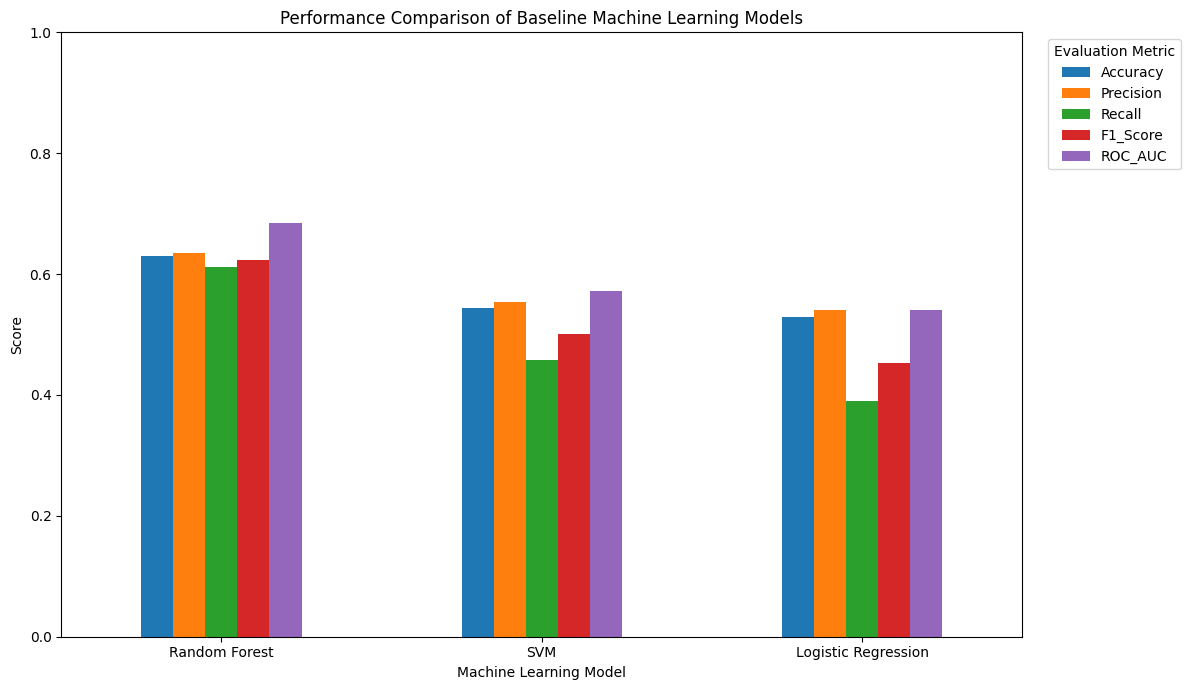

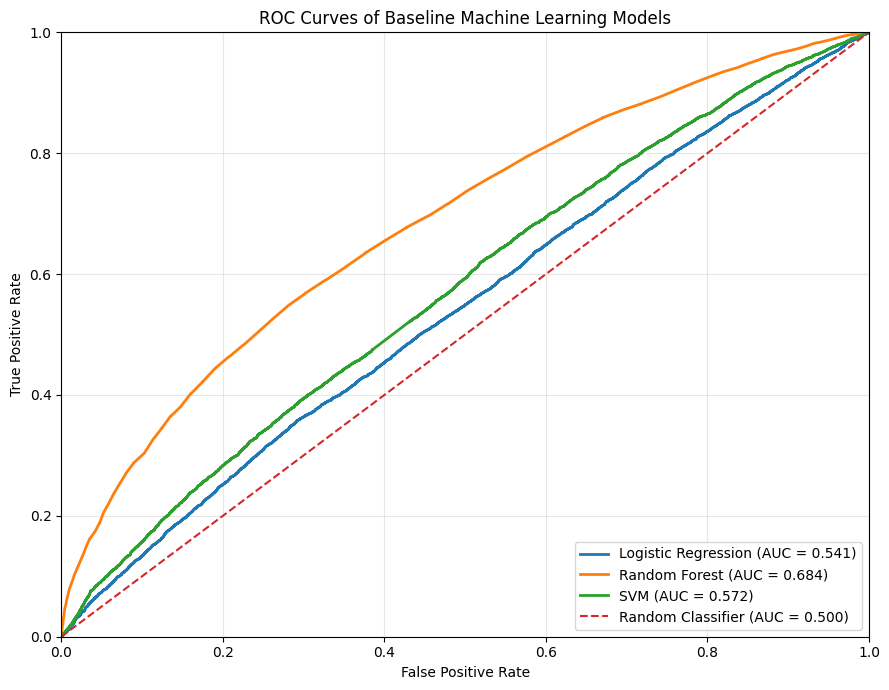


BEST-PERFORMING BASELINE MODEL
Model: Random Forest
Accuracy: 0.6299
Precision: 0.6346
Recall: 0.6125
F1-score: 0.6233
ROC-AUC: 0.6840


In [49]:
# ============================================================
# STEP 27 – VISUALISE BASELINE MODEL PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve


# ------------------------------------------------------------
# Display the model comparison table created in Step 26
# ------------------------------------------------------------

print("=" * 70)
print("BASELINE MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(results_df.round(4))


# ============================================================
# Plot 1 – Comparison of Evaluation Metrics
# ============================================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

plot_df = results_df.set_index("Model")[metrics_to_plot]


ax = plot_df.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title(
    "Performance Comparison of Baseline Machine Learning Models"
)

plt.xlabel("Machine Learning Model")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot 2 – ROC Curves
# ============================================================

plt.figure(
    figsize=(9, 7)
)


for model_name, model in models.items():

    # Obtain predicted probabilities for the positive class
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    # Obtain the ROC-AUC calculated in Step 26
    model_auc = results_df.loc[
        results_df["Model"] == model_name,
        "ROC_AUC"
    ].iloc[0]

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {model_auc:.3f})"
    )


# ------------------------------------------------------------
# Random classifier reference line
# ------------------------------------------------------------

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.500)"
)


plt.title(
    "ROC Curves of Baseline Machine Learning Models"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# Identify the best-performing baseline model
# ============================================================

best_model_row = results_df.iloc[0]

print("\n" + "=" * 70)
print("BEST-PERFORMING BASELINE MODEL")
print("=" * 70)

print(
    f"Model: {best_model_row['Model']}"
)

print(
    f"Accuracy: {best_model_row['Accuracy']:.4f}"
)

print(
    f"Precision: {best_model_row['Precision']:.4f}"
)

print(
    f"Recall: {best_model_row['Recall']:.4f}"
)

print(
    f"F1-score: {best_model_row['F1_Score']:.4f}"
)

print(
    f"ROC-AUC: {best_model_row['ROC_AUC']:.4f}"
)

## Step 28 — Precision–Recall Analysis of Baseline Models

In this step, Precision–Recall (PR) analysis is performed to provide an additional evaluation of the three baseline machine-learning models: Logistic Regression, Random Forest, and Support Vector Machine (SVM).

While ROC curves describe the trade-off between the true-positive rate and false-positive rate, Precision–Recall curves focus on the models' ability to identify positive drug–disease associations.

**Precision** represents the proportion of predicted positive associations that are actually positive, whereas **recall** represents the proportion of known positive associations that are successfully identified.

For each baseline model, predicted probabilities for the positive class are used to construct a Precision–Recall curve and calculate the **Average Precision (AP)** score. A higher AP score indicates better overall performance in ranking positive drug–disease associations.

The prevalence of the positive class in the test dataset is included as a reference baseline in the Precision–Recall plot.

The calculated Average Precision scores are added to the baseline model comparison table from Step 26. These results are considered alongside ROC-AUC, F1-score, precision, recall, and accuracy to provide a more comprehensive comparison of the baseline classifiers.


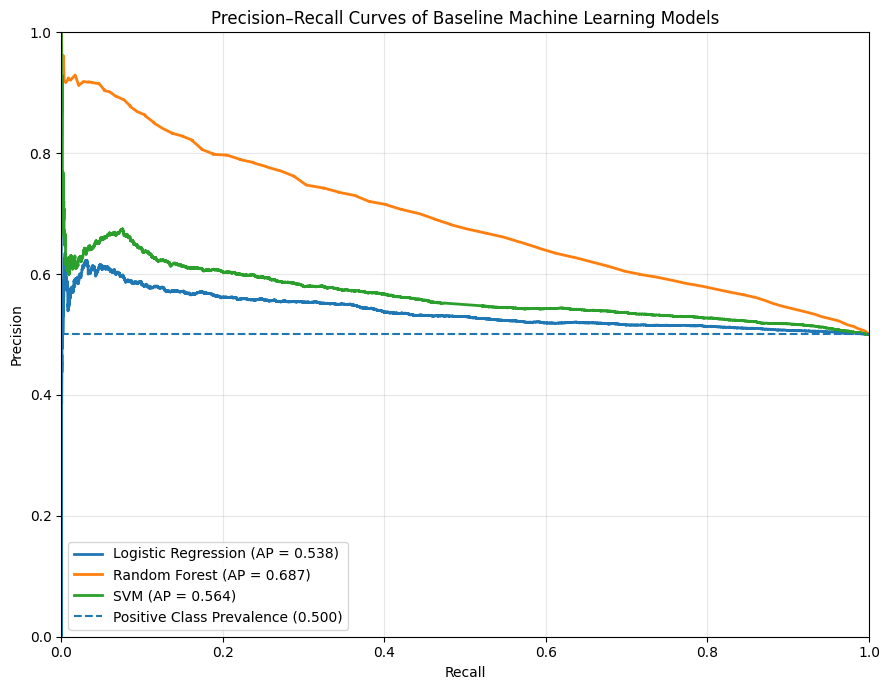


AVERAGE PRECISION COMPARISON


,Model,Average_Precision
0,Random Forest,0.6869
1,SVM,0.5642
2,Logistic Regression,0.5377



UPDATED BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
0,Random Forest,0.6299,0.6346,0.6125,0.6233,0.6840,0.6869
1,SVM,0.5443,0.5536,0.4584,0.5015,0.5721,0.5642
2,Logistic Regression,0.5297,0.5413,0.3898,0.4532,0.5409,0.5377



Saved: baseline_model_results_with_ap.csv


In [50]:
# ============================================================
# STEP 28 – PRECISION–RECALL ANALYSIS OF BASELINE MODELS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)


# ------------------------------------------------------------
# Store Average Precision results
# ------------------------------------------------------------

pr_results = []


# ------------------------------------------------------------
# Create Precision–Recall curves
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 7)
)


for model_name, model in models.items():

    # --------------------------------------------------------
    # Predict probability of the positive class
    # --------------------------------------------------------

    y_prob = model.predict_proba(X_test)[:, 1]


    # --------------------------------------------------------
    # Calculate Precision–Recall curve
    # --------------------------------------------------------

    precision_curve, recall_curve, thresholds = (
        precision_recall_curve(
            y_test,
            y_prob
        )
    )


    # --------------------------------------------------------
    # Calculate Average Precision
    # --------------------------------------------------------

    average_precision = average_precision_score(
        y_test,
        y_prob
    )


    # Store result
    pr_results.append({
        "Model": model_name,
        "Average_Precision": average_precision
    })


    # --------------------------------------------------------
    # Plot Precision–Recall curve
    # --------------------------------------------------------

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AP = {average_precision:.3f})"
        )
    )


# ------------------------------------------------------------
# Calculate positive-class prevalence
# ------------------------------------------------------------

positive_prevalence = y_test.mean()


# ------------------------------------------------------------
# Add baseline corresponding to random classification
# ------------------------------------------------------------

plt.axhline(
    y=positive_prevalence,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Positive Class Prevalence "
        f"({positive_prevalence:.3f})"
    )
)


# ------------------------------------------------------------
# Format plot
# ------------------------------------------------------------

plt.title(
    "Precision–Recall Curves of Baseline Machine Learning Models"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend(
    loc="lower left"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# Create Average Precision comparison table
# ============================================================

pr_results_df = pd.DataFrame(
    pr_results
)


pr_results_df = pr_results_df.sort_values(
    by="Average_Precision",
    ascending=False
).reset_index(
    drop=True
)


print("\n" + "=" * 70)
print("AVERAGE PRECISION COMPARISON")
print("=" * 70)

display(
    pr_results_df.round(4)
)


# ============================================================
# Add Average Precision to the existing results table
# ============================================================

results_df = results_df.merge(
    pr_results_df,
    on="Model",
    how="left"
)


# ------------------------------------------------------------
# Sort again according to ROC-AUC
# ------------------------------------------------------------

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(
    drop=True
)


print("\n" + "=" * 70)
print("UPDATED BASELINE MODEL COMPARISON")
print("=" * 70)

display(
    results_df.round(4)
)


# ------------------------------------------------------------
# Save updated evaluation results
# ------------------------------------------------------------

results_df.to_csv(
    "baseline_model_results_with_ap.csv",
    index=False
)


print(
    "\nSaved: baseline_model_results_with_ap.csv"
)

## Step 29 — Random Forest Feature Importance Analysis

Random Forest achieved the strongest overall performance among the three baseline machine-learning models—Logistic Regression, Random Forest, and Support Vector Machine (SVM)—based on ROC-AUC, Average Precision, F1-score, accuracy, precision, and recall.

To improve the interpretability of the best-performing baseline model, feature importance analysis is performed using the Random Forest classifier trained in Step 26.

Random Forest estimates feature importance based on the total reduction in impurity contributed by each feature across the decision trees in the ensemble. Higher importance values indicate that a feature contributes more strongly to the model's classification decisions.

The feature importance values are ranked from highest to lowest and visualised using a horizontal bar chart. The three most important features are also identified.

This analysis helps identify which drug-level and disease-level characteristics contribute most strongly to the classification of positive and candidate-negative drug–disease pairs.

Feature importance values are interpreted as measures of the relative contribution of the input variables to the model's predictions and should not be interpreted as evidence of causal biological relationships.


RANDOM FOREST FEATURE IMPORTANCE


,Rank,Feature,Importance
0,1,Max_Association_Score,0.1163
1,2,LogP,0.1162
2,3,Mean_Association_Score,0.1157
3,4,Total_Evidence,0.1156
4,5,MolWt,0.1132
5,6,Num_Targets,0.1126
6,7,TPSA,0.1089
7,8,Rotatable_Bonds,0.0649
8,9,HBA,0.0494
9,10,Ring_Count,0.0450


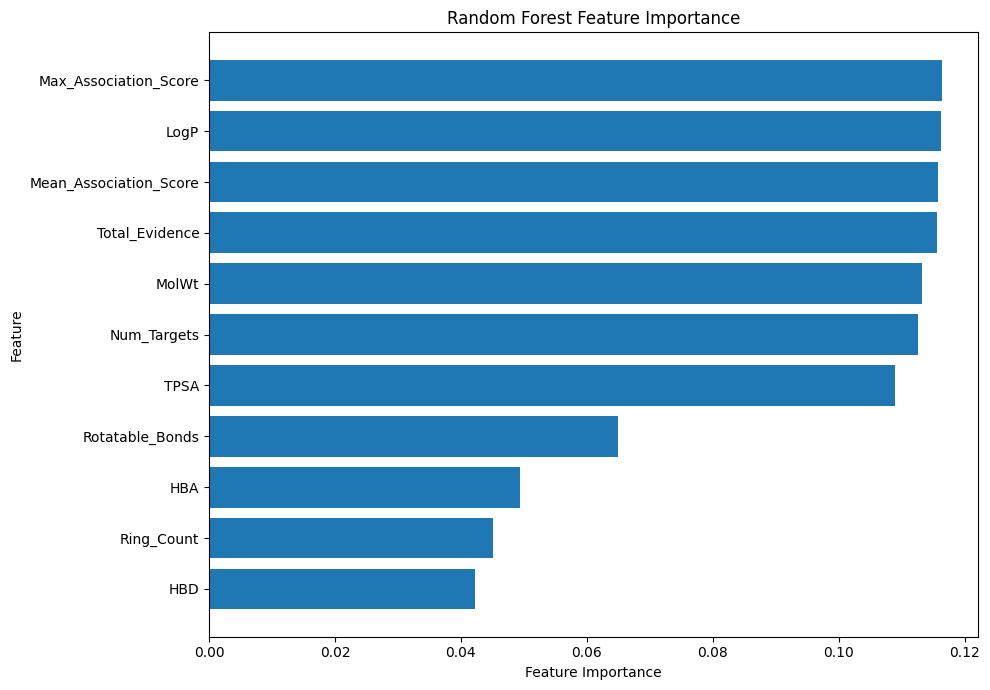


Sum of feature importance values: 1.0

TOP THREE MOST IMPORTANT FEATURES
1. Max_Association_Score: 0.1163
2. LogP: 0.1162
3. Mean_Association_Score: 0.1157

Saved: random_forest_feature_importance.csv


In [51]:
# ============================================================
# STEP 29 – RANDOM FOREST FEATURE IMPORTANCE ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Retrieve the trained Random Forest model from Step 26
# ------------------------------------------------------------

rf_model = models["Random Forest"]


# ------------------------------------------------------------
# Extract feature importance values
# ------------------------------------------------------------

feature_importances = rf_model.feature_importances_


# ------------------------------------------------------------
# Create feature importance DataFrame
# ------------------------------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
})


# ------------------------------------------------------------
# Sort features from most important to least important
# ------------------------------------------------------------

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(
    drop=True
)


# ------------------------------------------------------------
# Add ranking
# ------------------------------------------------------------

feature_importance_df.insert(
    0,
    "Rank",
    range(
        1,
        len(feature_importance_df) + 1
    )
)


# ------------------------------------------------------------
# Display feature importance table
# ------------------------------------------------------------

print("=" * 70)
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 70)

display(
    feature_importance_df.round(4)
)


# ============================================================
# Visualise feature importance
# ============================================================

plot_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=True
)


plt.figure(
    figsize=(10, 7)
)

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"]
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Check that feature importance values sum to approximately 1
# ------------------------------------------------------------

print(
    "\nSum of feature importance values:",
    round(feature_importances.sum(), 4)
)


# ------------------------------------------------------------
# Display the three most important features
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP THREE MOST IMPORTANT FEATURES")
print("=" * 70)

for _, row in feature_importance_df.head(3).iterrows():

    print(
        f"{int(row['Rank'])}. "
        f"{row['Feature']}: "
        f"{row['Importance']:.4f}"
    )


# ------------------------------------------------------------
# Save feature importance results
# ------------------------------------------------------------

feature_importance_df.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)


print(
    "\nSaved: random_forest_feature_importance.csv"
)

## Step 30 — Hyperparameter Tuning of the Random Forest Model

Random Forest achieved the strongest overall performance among the three baseline machine-learning models and was therefore selected for hyperparameter optimisation.

`GridSearchCV` was used to systematically evaluate combinations of Random Forest hyperparameters using five-fold cross-validation on the training dataset. The hyperparameters investigated were the number of trees (`n_estimators`), maximum tree depth (`max_depth`), number of features considered when searching for the best split (`max_features`), minimum number of samples required to split an internal node (`min_samples_split`), and minimum number of samples required at a leaf node (`min_samples_leaf`).

ROC-AUC was used as the optimisation criterion because the objective is to distinguish positive drug–disease associations from candidate-negative associations across different classification thresholds.

The held-out test dataset was not used during hyperparameter tuning. After the best hyperparameter combination was identified using cross-validation, the corresponding optimised Random Forest model was evaluated on the unchanged test dataset.

The tuned model was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, Average Precision, a confusion matrix, and a classification report. Its test-set performance was then compared directly with that of the baseline Random Forest model.

This approach allows hyperparameter optimisation to be performed using only the training data while preserving the independent test dataset for final performance evaluation.


In [52]:
# ============================================================
# STEP 30 – HYPERPARAMETER TUNING OF RANDOM FOREST
# ============================================================

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# Define a new Random Forest classifier for tuning
# ------------------------------------------------------------

rf_for_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)


# ------------------------------------------------------------
# Define hyperparameter grid
# ------------------------------------------------------------

rf_param_grid = {

    "n_estimators": [
        100,
        200
    ],

    "max_depth": [
        None,
        20
    ],

    "max_features": [
        "sqrt",
        "log2"
    ],

    "min_samples_split": [
        2,
        5
    ],

    "min_samples_leaf": [
        1,
        2
    ]
}


# ------------------------------------------------------------
# Configure GridSearchCV
# ------------------------------------------------------------

rf_grid_search = GridSearchCV(

    estimator=rf_for_tuning,

    param_grid=rf_param_grid,

    scoring="roc_auc",

    cv=5,

    n_jobs=-1,

    verbose=1,

    return_train_score=True
)


# ------------------------------------------------------------
# Perform hyperparameter tuning
# ------------------------------------------------------------

print("=" * 70)
print("RANDOM FOREST HYPERPARAMETER TUNING")
print("=" * 70)

print("\nStarting GridSearchCV...")

rf_grid_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Display best hyperparameters
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 70)

print(
    rf_grid_search.best_params_
)


# ------------------------------------------------------------
# Display best cross-validation ROC-AUC
# ------------------------------------------------------------

print(
    "\nBest cross-validation ROC-AUC:",
    round(
        rf_grid_search.best_score_,
        4
    )
)


# ------------------------------------------------------------
# Retrieve the best tuned Random Forest model
# ------------------------------------------------------------

best_rf_model = rf_grid_search.best_estimator_


# ============================================================
# Evaluate tuned model on the untouched test dataset
# ============================================================

rf_tuned_pred = best_rf_model.predict(
    X_test
)

rf_tuned_prob = best_rf_model.predict_proba(
    X_test
)[:, 1]


# ------------------------------------------------------------
# Calculate test performance
# ------------------------------------------------------------

rf_tuned_accuracy = accuracy_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_precision = precision_score(
    y_test,
    rf_tuned_pred,
    zero_division=0
)

rf_tuned_recall = recall_score(
    y_test,
    rf_tuned_pred,
    zero_division=0
)

rf_tuned_f1 = f1_score(
    y_test,
    rf_tuned_pred,
    zero_division=0
)

rf_tuned_roc_auc = roc_auc_score(
    y_test,
    rf_tuned_prob
)

rf_tuned_ap = average_precision_score(
    y_test,
    rf_tuned_prob
)


# ------------------------------------------------------------
# Display tuned model results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TUNED RANDOM FOREST – TEST SET PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy:          {rf_tuned_accuracy:.4f}"
)

print(
    f"Precision:         {rf_tuned_precision:.4f}"
)

print(
    f"Recall:            {rf_tuned_recall:.4f}"
)

print(
    f"F1-score:          {rf_tuned_f1:.4f}"
)

print(
    f"ROC-AUC:           {rf_tuned_roc_auc:.4f}"
)

print(
    f"Average Precision: {rf_tuned_ap:.4f}"
)


# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        rf_tuned_pred
    )
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_tuned_pred,
        digits=4
    )
)


# ============================================================
# Compare baseline and tuned Random Forest
# ============================================================

baseline_rf_row = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]


rf_comparison_df = pd.DataFrame({

    "Model": [
        "Baseline Random Forest",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        baseline_rf_row["Accuracy"],
        rf_tuned_accuracy
    ],

    "Precision": [
        baseline_rf_row["Precision"],
        rf_tuned_precision
    ],

    "Recall": [
        baseline_rf_row["Recall"],
        rf_tuned_recall
    ],

    "F1_Score": [
        baseline_rf_row["F1_Score"],
        rf_tuned_f1
    ],

    "ROC_AUC": [
        baseline_rf_row["ROC_AUC"],
        rf_tuned_roc_auc
    ],

    "Average_Precision": [
        baseline_rf_row["Average_Precision"],
        rf_tuned_ap
    ]

})


print("\n" + "=" * 70)
print("BASELINE VS TUNED RANDOM FOREST")
print("=" * 70)

display(
    rf_comparison_df.round(4)
)


# ------------------------------------------------------------
# Save tuning results
# ------------------------------------------------------------

rf_comparison_df.to_csv(
    "random_forest_baseline_vs_tuned.csv",
    index=False
)


# ------------------------------------------------------------
# Save complete GridSearchCV results
# ------------------------------------------------------------

rf_grid_results_df = pd.DataFrame(
    rf_grid_search.cv_results_
)

rf_grid_results_df.to_csv(
    "random_forest_gridsearch_results.csv",
    index=False
)


print(
    "\nSaved: random_forest_baseline_vs_tuned.csv"
)

print(
    "Saved: random_forest_gridsearch_results.csv"
)

RANDOM FOREST HYPERPARAMETER TUNING

Starting GridSearchCV...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

BEST RANDOM FOREST PARAMETERS
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best cross-validation ROC-AUC: 0.6713

TUNED RANDOM FOREST – TEST SET PERFORMANCE
Accuracy:          0.6332
Precision:         0.6360
Recall:            0.6228
F1-score:          0.6294
ROC-AUC:           0.6885
Average Precision: 0.6931

Confusion Matrix:
[[6424 3558]
 [3766 6218]]

Classification Report:
              precision    recall  f1-score   support

           0     0.6304    0.6436    0.6369      9982
           1     0.6360    0.6228    0.6294      9984

    accuracy                         0.6332     19966
   macro avg     0.6332    0.6332    0.6331     19966
weighted avg     0.6332    0.6332    0.6331     19966


BASELINE VS TUNED RANDOM FOREST


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
0,Baseline Random Forest,0.6299,0.6346,0.6125,0.6233,0.6840,0.6869
1,Tuned Random Forest,0.6332,0.6360,0.6228,0.6294,0.6885,0.6931



Saved: random_forest_baseline_vs_tuned.csv
Saved: random_forest_gridsearch_results.csv


## Step 31 — Generate and Rank New Drug–Disease Repurposing Candidates

In this step, the tuned Random Forest model obtained in Step 30 is applied to previously unseen drug–disease combinations to generate potential drug-repurposing candidates.

The labelled modelling dataset contains known positive associations and sampled candidate-negative associations that were used during model development. These drug–disease pairs are therefore excluded from candidate generation so that the resulting predictions represent combinations not present in the labelled modelling dataset.

The candidate-generation procedure is as follows:

1. Unique drugs and their molecular descriptor features are obtained from the final machine-learning dataset.
2. Unique diseases and their aggregated Open Targets features are obtained from the disease feature dataset.
3. Drug–disease combinations are generated by combining the available drugs with the available diseases.
4. Any drug–disease pair already present in the labelled modelling dataset is removed.
5. The remaining unseen pairs are scored using the tuned Random Forest model from Step 30.
6. For memory-efficient processing, drugs are processed in batches of 100. Within each batch, the 500 highest-scoring unseen drug–disease pairs are retained.
7. The retained candidates from all batches are combined and ranked globally according to their predicted positive-class probability.
8. The top 50 ranked candidates are extracted for further examination.

The resulting `Repurposing_Score` represents the model's predicted positive-class probability and is used as a ranking score. It should not be interpreted as a clinical probability that a drug will successfully treat a particular disease.

A validation check is performed to confirm that none of the top-ranked candidate pairs is already present in the labelled modelling dataset.

This procedure provides a computationally manageable approach for identifying high-scoring, previously unseen drug–disease combinations for subsequent analysis. The resulting candidates should be regarded as computational predictions requiring further biological and clinical validation.


In [53]:
# ============================================================
# STEP 31 – GENERATE AND RANK NEW DRUG–DISEASE CANDIDATES
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Features used by the trained model
# ------------------------------------------------------------

feature_columns = [
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count",
    "Num_Targets",
    "Mean_Association_Score",
    "Max_Association_Score",
    "Total_Evidence"
]


# ============================================================
# Step 31.1 – Create unique drug feature table
# ============================================================

drug_feature_columns = [
    "DrugBank_ID",
    "Drug_Name",
    "MolWt",
    "LogP",
    "TPSA",
    "HBD",
    "HBA",
    "Rotatable_Bonds",
    "Ring_Count"
]


drug_candidates_df = (
    final_ml_df[
        drug_feature_columns
    ]
    .drop_duplicates(
        subset=["DrugBank_ID"]
    )
    .reset_index(drop=True)
)


print(
    "Unique drugs available for candidate generation:",
    len(drug_candidates_df)
)


# ============================================================
# Step 31.2 – Create unique disease feature table
# ============================================================

disease_candidates_df = (
    disease_features_df[
        [
            "diseaseId",
            "Num_Targets",
            "Mean_Association_Score",
            "Max_Association_Score",
            "Total_Evidence"
        ]
    ]
    .drop_duplicates(
        subset=["diseaseId"]
    )
    .reset_index(drop=True)
)


print(
    "Unique diseases available for candidate generation:",
    len(disease_candidates_df)
)


# ============================================================
# Step 31.3 – Store all pairs already used in modelling
# ============================================================

existing_pairs = set(
    zip(
        final_ml_df["DrugBank_ID"],
        final_ml_df["diseaseId"]
    )
)


print(
    "Existing labelled pairs to exclude:",
    len(existing_pairs)
)


# ============================================================
# Step 31.4 – Generate unseen pairs in batches
# ============================================================

BATCH_SIZE = 100

TOP_N_PER_BATCH = 500

candidate_batches = []


for start in range(
    0,
    len(drug_candidates_df),
    BATCH_SIZE
):

    end = min(
        start + BATCH_SIZE,
        len(drug_candidates_df)
    )

    drug_batch = (
        drug_candidates_df
        .iloc[start:end]
        .copy()
    )


    # --------------------------------------------------------
    # Cross join drugs with diseases
    # --------------------------------------------------------

    batch_pairs = drug_batch.merge(
        disease_candidates_df,
        how="cross"
    )


    # --------------------------------------------------------
    # Remove pairs already present in final_ml_df
    # --------------------------------------------------------

    pair_index = pd.MultiIndex.from_arrays(
        [
            batch_pairs["DrugBank_ID"],
            batch_pairs["diseaseId"]
        ]
    )


    existing_index = pd.MultiIndex.from_tuples(
        existing_pairs
    )


    unseen_mask = ~pair_index.isin(
        existing_index
    )


    batch_pairs = (
        batch_pairs[
            unseen_mask
        ]
        .copy()
    )


    # --------------------------------------------------------
    # Predict positive-class probability
    # --------------------------------------------------------

    batch_pairs[
        "Repurposing_Score"
    ] = best_rf_model.predict_proba(
        batch_pairs[
            feature_columns
        ]
    )[:, 1]


    # --------------------------------------------------------
    # Keep only strongest candidates from this batch
    # --------------------------------------------------------

    batch_top = (
        batch_pairs
        .sort_values(
            by="Repurposing_Score",
            ascending=False
        )
        .head(
            TOP_N_PER_BATCH
        )
    )


    candidate_batches.append(
        batch_top
    )


    print(
        f"Processed drugs {start + 1} to {end}"
    )


# ============================================================
# Step 31.5 – Combine batch results
# ============================================================

repurposing_candidates_df = pd.concat(
    candidate_batches,
    ignore_index=True
)


# ------------------------------------------------------------
# Rank candidates globally
# ------------------------------------------------------------

repurposing_candidates_df = (
    repurposing_candidates_df
    .sort_values(
        by="Repurposing_Score",
        ascending=False
    )
    .reset_index(drop=True)
)


repurposing_candidates_df.insert(
    0,
    "Rank",
    range(
        1,
        len(repurposing_candidates_df) + 1
    )
)


# ============================================================
# Step 31.6 – Display top-ranked candidates
# ============================================================

TOP_N = 50


top_candidates_df = (
    repurposing_candidates_df
    .head(TOP_N)
    .copy()
)


print("\n" + "=" * 80)

print(
    f"TOP {TOP_N} NEW DRUG–DISEASE "
    "REPURPOSING CANDIDATES"
)

print("=" * 80)


display(
    top_candidates_df[
        [
            "Rank",
            "DrugBank_ID",
            "Drug_Name",
            "diseaseId",
            "Repurposing_Score"
        ]
    ].round(4)
)


# ============================================================
# Step 31.7 – Validation checks
# ============================================================

top_candidate_pairs = set(
    zip(
        top_candidates_df["DrugBank_ID"],
        top_candidates_df["diseaseId"]
    )
)


overlap_with_existing = (
    top_candidate_pairs
    .intersection(
        existing_pairs
    )
)


print(
    "\nTop candidate pairs already present "
    "in labelled dataset:",
    len(overlap_with_existing)
)


print(
    "\nHighest repurposing score:",
    round(
        top_candidates_df[
            "Repurposing_Score"
        ].max(),
        4
    )
)


print(
    "Lowest score among top",
    TOP_N,
    ":",
    round(
        top_candidates_df[
            "Repurposing_Score"
        ].min(),
        4
    )
)


# ============================================================
# Step 31.8 – Save results
# ============================================================

top_candidates_df.to_csv(
    "top_50_drug_repurposing_candidates.csv",
    index=False
)


repurposing_candidates_df.to_csv(
    "ranked_drug_repurposing_candidates.csv",
    index=False
)


print(
    "\nSaved: top_50_drug_repurposing_candidates.csv"
)

print(
    "Saved: ranked_drug_repurposing_candidates.csv"
)

Unique drugs available for candidate generation: 5200
Unique diseases available for candidate generation: 3273
Existing labelled pairs to exclude: 99826
Processed drugs 1 to 100
Processed drugs 101 to 200
Processed drugs 201 to 300
Processed drugs 301 to 400
Processed drugs 401 to 500
Processed drugs 501 to 600
Processed drugs 601 to 700
Processed drugs 701 to 800
Processed drugs 801 to 900
Processed drugs 901 to 1000
Processed drugs 1001 to 1100
Processed drugs 1101 to 1200
Processed drugs 1201 to 1300
Processed drugs 1301 to 1400
Processed drugs 1401 to 1500
Processed drugs 1501 to 1600
Processed drugs 1601 to 1700
Processed drugs 1701 to 1800
Processed drugs 1801 to 1900
Processed drugs 1901 to 2000
Processed drugs 2001 to 2100
Processed drugs 2101 to 2200
Processed drugs 2201 to 2300
Processed drugs 2301 to 2400
Processed drugs 2401 to 2500
Processed drugs 2501 to 2600
Processed drugs 2601 to 2700
Processed drugs 2701 to 2800
Processed drugs 2801 to 2900
Processed drugs 2901 to 300

,Rank,DrugBank_ID,Drug_Name,diseaseId,Repurposing_Score
0,1,DB11823,Esketamine,MONDO_0000675,0.9870
1,2,DB00681,Amphotericin B,MONDO_0002614,0.9864
2,3,DB00681,Amphotericin B,EFO_0009429,0.9855
3,4,DB12874,Quizartinib,MONDO_0005105,0.9838
4,5,DB13489,Bamipine,MONDO_0002009,0.9823
5,6,DB00681,Amphotericin B,EFO_0009444,0.9818
6,7,DB00567,Cephalexin,MONDO_0005113,0.9815
7,8,DB00681,Amphotericin B,MONDO_0015474,0.9769
8,9,DB00681,Amphotericin B,MONDO_0005893,0.9769
9,10,DB00681,Amphotericin B,MONDO_0006722,0.9760



Top candidate pairs already present in labelled dataset: 0

Highest repurposing score: 0.987
Lowest score among top 50 : 0.9585

Saved: top_50_drug_repurposing_candidates.csv
Saved: ranked_drug_repurposing_candidates.csv


## Step 32 — Mapping Candidate Disease Identifiers to Disease Names

The candidate drug–disease associations generated in Step 31 contain Open Targets disease identifiers, including identifiers from disease ontologies such as MONDO, EFO, and other identifier systems represented in the Open Targets disease metadata.

Although these identifiers uniquely represent disease or phenotype entities, descriptive names are required to make the final repurposing results interpretable.

In this step, the Open Targets disease metadata is loaded, and each candidate `diseaseId` is mapped to its corresponding disease name using the disease identifier and name fields.

The disease names are then added to the top 50 ranked candidate table, producing an interpretable list containing the drug identifier, drug name, disease identifier, disease name, and model-generated repurposing score.

A validation check is performed to determine whether any of the top 50 candidate disease identifiers could not be mapped to a disease name.

The top 20 candidates are displayed for inspection, and the 10 highest-ranked candidates are retained as the final model-ranked repurposing candidates.

The `Repurposing_Score` represents the tuned Random Forest model's positive-class score used for ranking candidate associations. It should not be interpreted as a clinical probability that a drug will successfully treat a particular disease. The resulting candidates represent computational predictions that require further biological and clinical validation.


In [54]:
# ============================================================
# STEP 32 – MAP DISEASE IDs TO DISEASE NAMES
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# File path
# ------------------------------------------------------------

DISEASE_FILE = (
    "/Users/sankhadeep/Desktop/DrugBank/"
    "OpenTargets/disease/disease.parquet"
)


# ============================================================
# Step 32.1 – Load disease metadata
# ============================================================

disease_metadata_df = pd.read_parquet(
    DISEASE_FILE
)


print(
    "Disease metadata shape:",
    disease_metadata_df.shape
)


print(
    "\nAvailable columns:"
)

print(
    disease_metadata_df.columns.tolist()
)


# ============================================================
# Step 32.2 – Keep disease ID and disease name
# ============================================================

disease_name_df = (
    disease_metadata_df[
        [
            "id",
            "name"
        ]
    ]
    .rename(
        columns={
            "id": "diseaseId",
            "name": "Disease_Name"
        }
    )
    .drop_duplicates(
        subset="diseaseId"
    )
    .reset_index(drop=True)
)


print(
    "\nNumber of diseases:",
    len(disease_name_df)
)


# ============================================================
# Step 32.3 – Add disease names to Top 50 candidates
# ============================================================

top_candidates_named_df = (
    top_candidates_df
    .merge(
        disease_name_df,
        on="diseaseId",
        how="left"
    )
)


# ============================================================
# Step 32.4 – Check mapping
# ============================================================

missing_names = (
    top_candidates_named_df[
        "Disease_Name"
    ]
    .isna()
    .sum()
)


print(
    "\nTop 50 candidate rows:",
    len(top_candidates_named_df)
)

print(
    "Disease names missing:",
    missing_names
)


# ============================================================
# Step 32.5 – Display Top 20
# ============================================================

print("\n" + "=" * 90)

print(
    "TOP 20 DRUG–DISEASE REPURPOSING CANDIDATES"
)

print("=" * 90)


display(
    top_candidates_named_df[
        [
            "Rank",
            "DrugBank_ID",
            "Drug_Name",
            "diseaseId",
            "Disease_Name",
            "Repurposing_Score"
        ]
    ]
    .head(20)
    .round(4)
)


# ============================================================
# Step 32.6 – Final Top 10
# ============================================================

final_top_10_candidates_df = (
    top_candidates_named_df
    .head(10)
    .copy()
)


print("\n" + "=" * 90)

print(
    "FINAL TOP 10 MODEL-RANKED REPURPOSING CANDIDATES"
)

print("=" * 90)


display(
    final_top_10_candidates_df[
        [
            "Rank",
            "DrugBank_ID",
            "Drug_Name",
            "diseaseId",
            "Disease_Name",
            "Repurposing_Score"
        ]
    ]
    .round(4)
)


# ============================================================
# Step 32.7 – Save Results
# ============================================================

top_candidates_named_df.to_csv(
    "top_50_repurposing_candidates_with_disease_names.csv",
    index=False
)


final_top_10_candidates_df.to_csv(
    "final_top_10_repurposing_candidates.csv",
    index=False
)


print(
    "\nSaved: "
    "top_50_repurposing_candidates_with_disease_names.csv"
)

print(
    "Saved: final_top_10_repurposing_candidates.csv"
)

Disease metadata shape: (47080, 18)

Available columns:
['id', 'code', 'name', 'description', 'dbXRefs', 'parents', 'exactSynonyms', 'relatedSynonyms', 'narrowSynonyms', 'broadSynonyms', 'obsoleteTerms', 'obsoleteXRefs', 'children', 'ancestors', 'therapeuticAreas', 'descendants', 'ontology', 'synonyms']

Number of diseases: 47080

Top 50 candidate rows: 50
Disease names missing: 0

TOP 20 DRUG–DISEASE REPURPOSING CANDIDATES


,Rank,DrugBank_ID,Drug_Name,diseaseId,Disease_Name,Repurposing_Score
0,1,DB11823,Esketamine,MONDO_0000675,pain agnosia,0.9870
1,2,DB00681,Amphotericin B,MONDO_0002614,bone inflammation disease,0.9864
2,3,DB00681,Amphotericin B,EFO_0009429,Mycobacterium infection,0.9855
3,4,DB12874,Quizartinib,MONDO_0005105,melanoma,0.9838
4,5,DB13489,Bamipine,MONDO_0002009,major depressive disorder,0.9823
5,6,DB00681,Amphotericin B,EFO_0009444,hypoxia,0.9818
6,7,DB00567,Cephalexin,MONDO_0005113,bacterial infectious disease,0.9815
7,8,DB00681,Amphotericin B,MONDO_0015474,cryptosporidiosis,0.9769
8,9,DB00681,Amphotericin B,MONDO_0005893,pancreatic endocrine carcinoma,0.9769
9,10,DB00681,Amphotericin B,MONDO_0006722,dental fluorosis,0.9760



FINAL TOP 10 MODEL-RANKED REPURPOSING CANDIDATES


,Rank,DrugBank_ID,Drug_Name,diseaseId,Disease_Name,Repurposing_Score
0,1,DB11823,Esketamine,MONDO_0000675,pain agnosia,0.9870
1,2,DB00681,Amphotericin B,MONDO_0002614,bone inflammation disease,0.9864
2,3,DB00681,Amphotericin B,EFO_0009429,Mycobacterium infection,0.9855
3,4,DB12874,Quizartinib,MONDO_0005105,melanoma,0.9838
4,5,DB13489,Bamipine,MONDO_0002009,major depressive disorder,0.9823
5,6,DB00681,Amphotericin B,EFO_0009444,hypoxia,0.9818
6,7,DB00567,Cephalexin,MONDO_0005113,bacterial infectious disease,0.9815
7,8,DB00681,Amphotericin B,MONDO_0015474,cryptosporidiosis,0.9769
8,9,DB00681,Amphotericin B,MONDO_0005893,pancreatic endocrine carcinoma,0.9769
9,10,DB00681,Amphotericin B,MONDO_0006722,dental fluorosis,0.9760



Saved: top_50_repurposing_candidates_with_disease_names.csv
Saved: final_top_10_repurposing_candidates.csv
